# Lab 4: Ecology Models and Snow Leopard Tracking
**Course:** Environmental Science for Sustainable Development
**Source:** Ecology Lab, S. Hsiang
**Completed by:** Aaron Scherf

This report explores various models of ecology and modeled populations dynamics. Section 1 solves a system of equations by plotting and root finding. Section 2 studies koala, beetle and snake population models built on the discrete logistic equation. Section 3 estimates the size of a snow leopard population from camera-trap counts using Monte Carlo simulation. Each section states the model and its assumptions, shows the simulation results, and interprets them.


## Approach and conventions
- The simulations are written in Python, and the scripts are included with each section.
- Each simulation section gives its plan (inputs, outputs, array dimensions, indexing and information flow), the code, the plots and a written interpretation.
- Plots are titled and their axes labeled.
- Chosen initial values and modeling assumptions are stated where they are made.


# 1. Solving difficult equations
## 1.1 Plot the two surfaces
Create a two-dimensional grid from -5 to 5 in both x and y, spaced by 0.1. Plot the population surface z = x² + sin(y) + xy. On the same axes, plot the conservation surface z = x + y. Describe their shapes and where they appear to meet.

**Method:** grid construction and surface plots.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

x_values = np.arange(-5.0, 5.0 + 0.05, 0.1)
y_values = np.arange(-5.0, 5.0 + 0.05, 0.1)
X, Y = np.meshgrid(x_values, y_values)

z_population = X**2 + np.sin(Y) + X * Y
z_conservation = X + Y

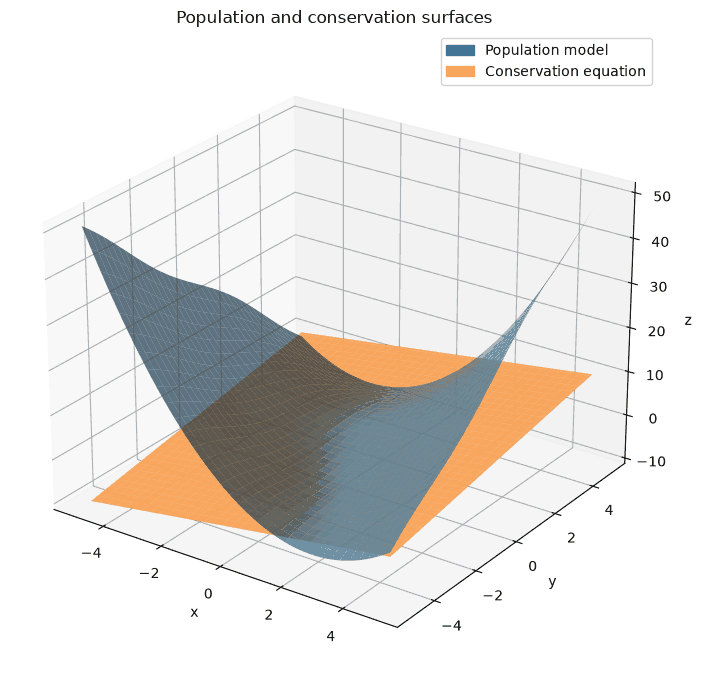

In [2]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, Y, z_population, color="tab:blue", alpha=0.65,
                rstride=3, cstride=3)
ax.plot_surface(X, Y, z_conservation, color="tab:orange", alpha=0.65,
                rstride=3, cstride=3)
ax.set(xlabel="x", ylabel="y", zlabel="z",
       title="Population and conservation surfaces")
ax.legend(handles=[Patch(color="tab:blue", label="Population model"),
                   Patch(color="tab:orange", label="Conservation equation")])
ax.view_init(elev=25, azim=-55)
plt.tight_layout()
plt.show()

**Response (1.1):** The population surface can be rewritten as z = (x + y/2)² − y²/4 + sin(y). It is a saddle (the x² + xy part rises in one direction and falls in the perpendicular one) with a sine ripple in y. On the grid its values run from about −7 to about 51. The conservation surface z = x + y is a flat plane tilted upward in both x and y. The saddle passes through the plane in a band across the middle of the grid, and the two surfaces meet where x² + sin(y) + xy = x + y, which simplifies to (x − 1)(x + y) + sin(y) = 0. Section 1.2 plots that curve exactly.


## 1.2 Find and interpret the intersection
Plot the intersection of the surfaces. At x = 1, how many y values satisfy both equations? What is z at each solution? Explain how the plot and numerical estimates support the answer.

**Method:** intersection plot and x = 1 calculations.

In [3]:
from scipy.optimize import brentq

# The zero contour of this difference is the intersection in the x-y plane.
difference = z_population - z_conservation
x_fixed = 1.0

def difference_at_fixed_x(y):
    return x_fixed**2 + np.sin(y) + x_fixed * y - (x_fixed + y)

y_scan = np.linspace(-5.0, 5.0, 2001)
sample_values = difference_at_fixed_x(y_scan)
roots = []
for i in range(len(y_scan) - 1):
    if np.isclose(sample_values[i], 0.0, atol=1e-12):
        roots.append(y_scan[i])
    elif sample_values[i] * sample_values[i + 1] < 0:
        roots.append(brentq(difference_at_fixed_x, y_scan[i], y_scan[i + 1]))
if np.isclose(sample_values[-1], 0.0, atol=1e-12):
    roots.append(y_scan[-1])

y_roots = np.array(sorted(set(np.round(roots, 10))))
z_roots = x_fixed + y_roots

print(f"Number of solutions at x = {x_fixed:g}: {len(y_roots)}")
for y_value, z_value in zip(y_roots, z_roots):
    print(f"y = {y_value:.6f}, z = {z_value:.6f}")

Number of solutions at x = 1: 3
y = -3.141593, z = -2.141593
y = 0.000000, z = 1.000000
y = 3.141593, z = 4.141593


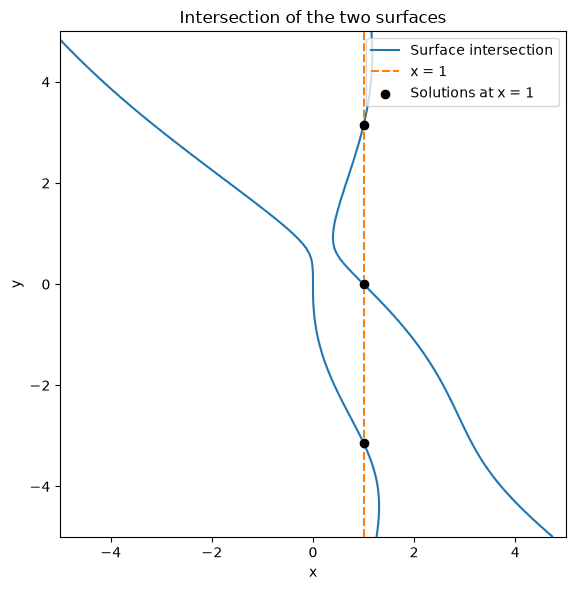

In [4]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.contour(X, Y, difference, levels=[0], colors="tab:blue")
ax.plot([], [], color="tab:blue", label="Surface intersection")
ax.axvline(x_fixed, color="tab:orange", linestyle="--", label="x = 1")
ax.scatter(np.full_like(y_roots, x_fixed), y_roots, color="black",
           zorder=3, label="Solutions at x = 1")
ax.set(xlabel="x", ylabel="y", xlim=(-5, 5), ylim=(-5, 5),
       title="Intersection of the two surfaces")
ax.set_aspect("equal")
ax.legend()
plt.tight_layout()
plt.show()

**Response (1.2):** The intersection is the zero contour of z_population − z_conservation = (x − 1)(x + y) + sin(y). On the line x = 1 the first term vanishes, so the condition becomes sin(y) = 0, giving y = −π, 0 and π within the grid (±2π lie outside −5 ≤ y ≤ 5). That is **3 values of y**. Because both surfaces agree at an intersection, z = x + y = 1 + y at each: z ≈ −2.1416 at y = −π, z = 1 at y = 0, and z ≈ 4.1416 at y = π. The plot shows the vertical line x = 1 crossing the intersection curve at three points, and a numerical root search along x = 1 returns the same three values.


# 2. Koala population models
## 2.1 Unrestricted growth: assumptions and plan
Given one-third mature males, one-third mature females, one-third juveniles, and a one-half annual birth probability per mature female, what is the growth parameter r in N(t+1) = N(t) + rN(t)? What extra information is needed to find population at a specified time? Choose and report an initial population μ.

Before coding, draw the input and output arrays, their dimensions and indices, and the yearly calculation flow.

**Heuristic array and computation plan (zero-based indices):**

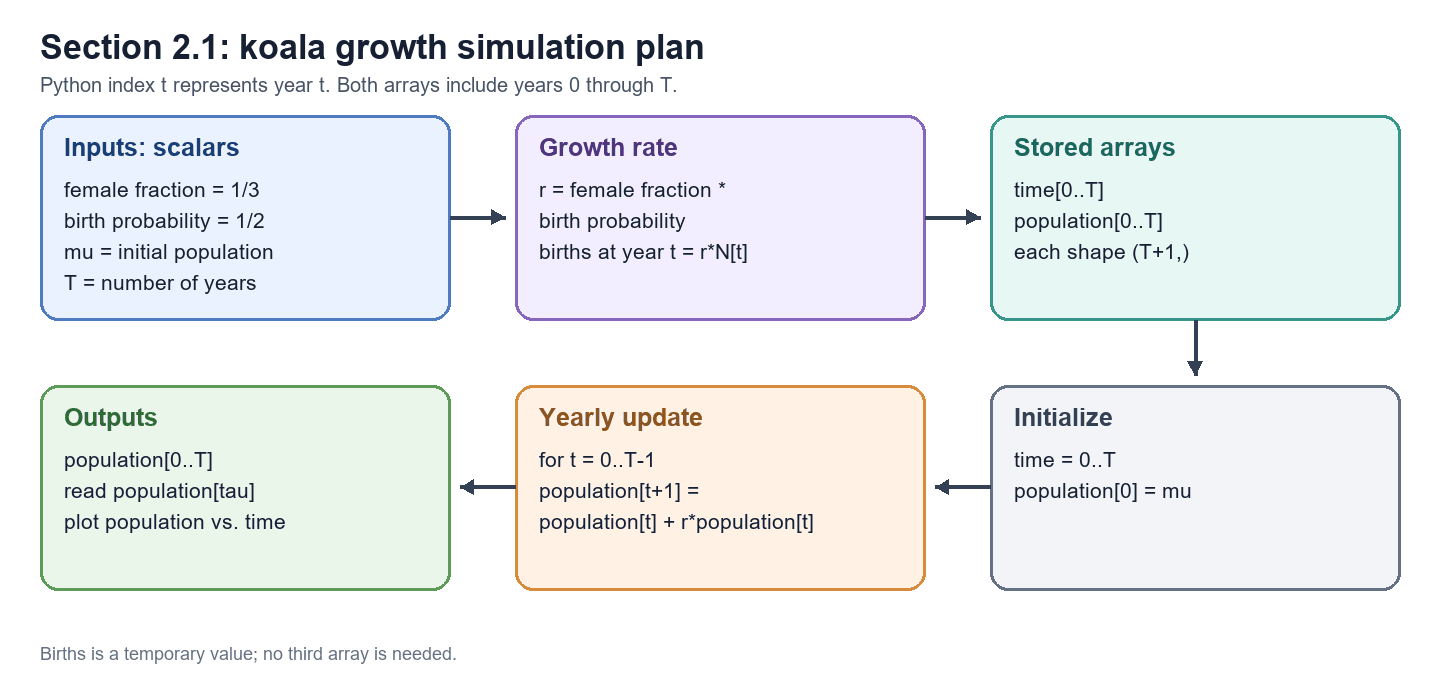

The stored time and population arrays each have shape (T+1,). Expected births are a temporary value in each yearly update. The initial population is mu = 120 (section 2.2); the answers to the 2.1 questions follow.

**Response (2.1):** Each year only the mature females can give birth: one third of the population, each producing one baby with probability 1/2. So r = (1/3)(1/2) = **1/6** per year, assuming the one-third / one-third / one-third age structure stays constant and ignoring deaths. To compute the population at a particular time τ we also need the **initial population** μ = N(0) (and the number of years τ). The solution is then N(τ) = μ(1 + r)^τ = μ(7/6)^τ. The chosen starting value is μ = 120.


## 2.2 Simulate unrestricted growth
Use one-year time steps to compute population over time from μ. Plot population against time and describe its behavior. Include the script and the plot.

**Method:** growth simulation and plot.

In [5]:
female_fraction = 1 / 3
birth_probability = 1 / 2
r_koala = female_fraction * birth_probability
mu = 120.0  # Chosen initial population
years = 80
time = np.arange(years + 1)
population = np.empty(years + 1, dtype=float)
population[0] = mu
for t in range(years):
    expected_births = r_koala * population[t]
    population[t + 1] = population[t] + expected_births
print(f"r = {r_koala:.6f}; N0 = {mu:g}")

r = 0.166667; N0 = 120


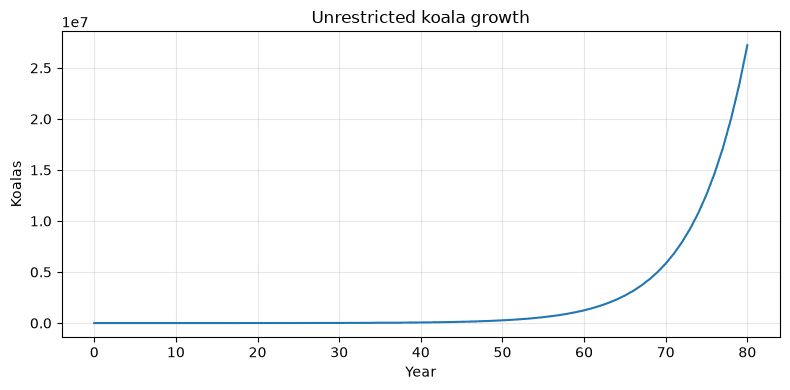

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(time, population)
ax.set(xlabel="Year", ylabel="Koalas", title="Unrestricted koala growth")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Response (2.2):** With r = 1/6 and μ = 120 the population grows exponentially, N(t) = 120(7/6)^t. It doubles about every 4.5 years and reaches roughly 27 million koalas after 80 years, so the plot is a curve that bends ever more steeply upward with no limit. That is unrealistic for a fixed forest, which motivates the carrying-capacity model in 2.3.


## 2.3 Carrying capacity: algebra and plan
A fixed forest has 5,000 eucalyptus trees; each koala needs five trees. Determine koala carrying capacity K. For the discrete logistic update N(t+1) = N(t) + rN(t)[1 − N(t)/K], check algebraically the stated growth or decline when N is below or above K, and the small-population limit.

Plan the arrays and update order before coding.

**Heuristic array and computation plan (zero-based indices):** the same model is used for koalas (2.4) and for beetles alone (2.5), with different parameters.

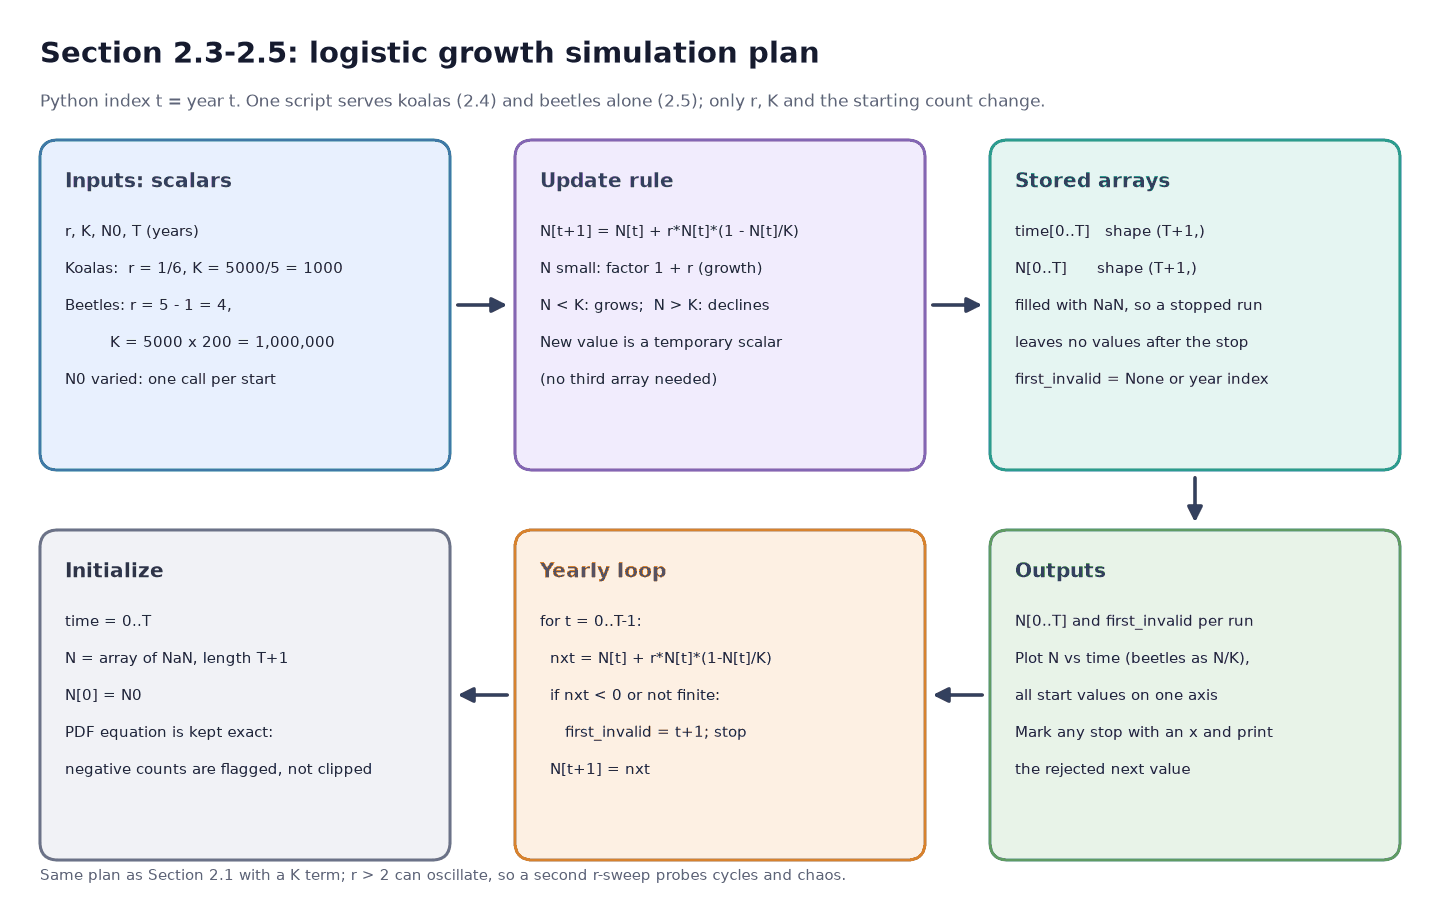

**Derivation / plan:** Each koala needs 5 trees, so K = 5000 / 5 = **1000 koalas**. The logistic update changes the population by N(t+1) − N(t) = r·N(t)·(1 − N(t)/K).
- If N < K, the bracket 1 − N/K is positive, so the population increases.
- If N = K, the bracket is zero, so the population does not change (an equilibrium; N = 0 is the other).
- If N > K, the bracket is negative, so the population decreases.
- If N ≪ K, the bracket is close to 1, so N(t+1) ≈ N(t) + r·N(t): the unrestricted growth model of 2.1 is recovered.

The yearly change per koala falls linearly from r at N = 0 to zero at K. Near the equilibrium, the slope of the update is 1 − r, so the approach to K is smooth when 0 < r < 1, overshoots K but still settles for 1 < r < 2, and no longer settles for r > 2 (used in 2.4). The computation plan is shown in the diagram above.

## 2.4 Characterize discrete logistic dynamics
Simulate several initial populations. How many types of behavior arise? Are there stable, indefinitely oscillating, or chaotic solutions? What in the model allows oscillations, and are they a numerical artifact or a plausible feature of nature? Use at most two plots, with multiple runs per plot if useful.

**Method:** initial-condition experiments; at most two plots.

In [7]:
eucalyptus_trees = 5000
trees_per_koala = 5
K_koala = eucalyptus_trees / trees_per_koala

def simulate_logistic(initial, rate, capacity, years):
    # Keep the PDF's update exact; stop if a negative count would occur.
    values = np.full(years + 1, np.nan)
    values[0] = initial
    for t in range(years):
        n = values[t]
        next_n = n + rate * n * (1 - n / capacity)
        if not np.isfinite(next_n) or next_n < 0:
            return values, t + 1
        values[t + 1] = next_n
    return values, None

years_logistic = 100
time_logistic = np.arange(years_logistic + 1)
initial_koalas = [50, 250, 800, 1000, 1500]
koala_runs = {}
for n0 in initial_koalas:
    trajectory, invalid_year = simulate_logistic(n0, r_koala, K_koala, years_logistic)
    koala_runs[n0] = trajectory
    print(f"Koalas N0={n0}: first invalid year = {invalid_year}")
print(f"Koala carrying capacity = {K_koala:g}")

Koalas N0=50: first invalid year = None
Koalas N0=250: first invalid year = None
Koalas N0=800: first invalid year = None
Koalas N0=1000: first invalid year = None
Koalas N0=1500: first invalid year = None
Koala carrying capacity = 1000


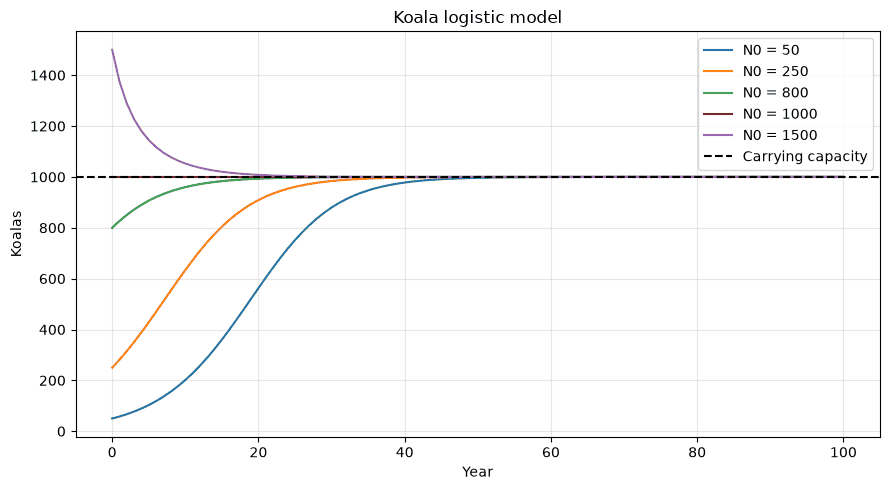

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for n0, trajectory in koala_runs.items():
    ax.plot(time_logistic, trajectory, label=f"N0 = {n0}")
ax.axhline(K_koala, color="black", linestyle="--", label="Carrying capacity")
ax.set(xlabel="Year", ylabel="Koalas", title="Koala logistic model")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
# Second plot for 2.4: the same update for larger growth rates. These r values are
# exploratory (the koala's own r is 1/6); K and the starting count are the koala values.
sweep_rates = [1.5, 2.2, 2.5, 2.9, 3.2]
sweep_years = 40
sweep_time = np.arange(sweep_years + 1)
sweep_runs = {}
for rate in sweep_rates:
    trajectory, invalid_year = simulate_logistic(100, rate, K_koala, sweep_years)
    sweep_runs[rate] = (trajectory, invalid_year)
    if invalid_year is None:
        print(f"r={rate:g}: last four values / K = {np.round(trajectory[-4:] / K_koala, 3)}")
    else:
        last = invalid_year - 1
        print(f"r={rate:g}: next value after year {last} is negative; "
              f"first invalid year = {invalid_year}")

r=1.5: last four values / K = [1. 1. 1. 1.]
r=2.2: last four values / K = [1.163 0.746 1.163 0.746]
r=2.5: last four values / K = [1.225 0.536 1.158 0.701]
r=2.9: last four values / K = [0.893 1.17  0.593 1.293]
r=3.2: next value after year 4 is negative; first invalid year = 5


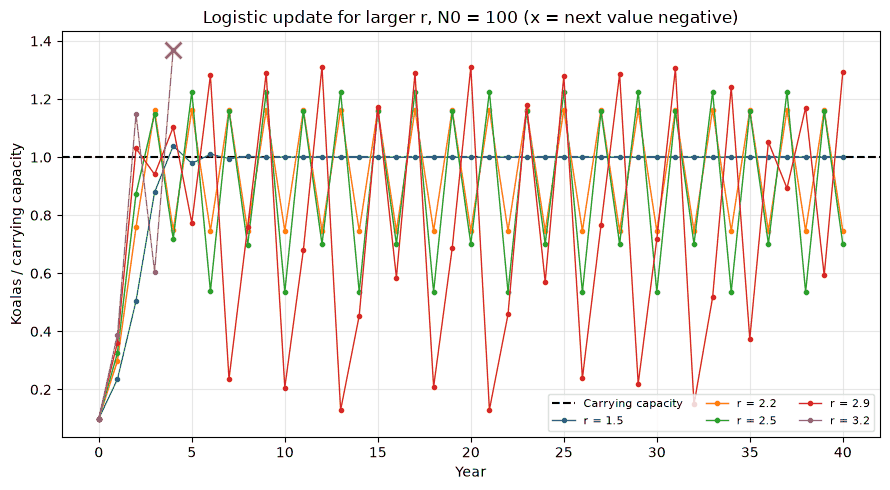

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(1, color="black", linestyle="--", label="Carrying capacity")
for rate, (trajectory, invalid_year) in sweep_runs.items():
    line, = ax.plot(sweep_time, trajectory / K_koala, marker="o", markersize=3,
                    linewidth=1, label=f"r = {rate:g}")
    if invalid_year is not None:
        last = invalid_year - 1
        ax.plot(last, trajectory[last] / K_koala, "x", color=line.get_color(),
                markersize=11, markeredgewidth=2.5)
ax.set(xlabel="Year", ylabel="Koalas / carrying capacity",
       title="Logistic update for larger r, N0 = 100 (x = next value negative)")
ax.legend(ncol=3, fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Response (2.4):** *With the koala's own r = 1/6* (first plot) every start settles smoothly on K = 1000: starts of 50, 250 and 800 rise in an S-shaped curve (50 reaches 950 in 36 years), 1000 stays put, and 1500 falls (1375, 1289, 1227, …). N = 0 is also an equilibrium but is unstable. An update from above 7000 koalas would go negative, but no sensible start is that large. *With larger growth rates* (second plot, exploratory values of r) the same equation gives more types of behavior:
- r < 1: smooth approach to K (as above).
- 1 < r < 2: damped oscillation. The population overshoots K and then settles (r = 1.5 settles within a few years).
- r > 2: a stable cycle that never settles (r = 2.2 alternates between about 1163 and 746 forever; r = 2.5 repeats a 4-year cycle of about 1225, 536, 1158 and 701).
- r ≈ 2.6 to 3: irregular, bounded motion with no repeating pattern (r = 2.9), which is chaotic.
- r above 3 (r = 3.2): an overshoot large enough to make the next population negative (year 5), so the model breaks down.

So five types of behavior can be produced (smooth approach, damped oscillation, stable cycles, chaos, and overshoot to negative values). Stable solutions exist for every r below 2; indefinitely oscillating and chaotic solutions exist, but only for large r. What allows oscillation is that next year's population is computed from this year's population alone, with a fixed one-year step: when r is large, growth at low density overshoots K, and the density correction applied a year later overshoots in the other direction.

**Discussion note (numerical artifact or feature of nature?):** The question can be argued both ways, so both views are given. *For an artifact:* the continuous-time logistic equation never oscillates. Cycles and chaos appear only when growth is applied in fixed one-year steps with a large r, and the exact cycle values, the r at which chaos begins, and the negative populations all depend on that choice of step. *For a feature of nature:* what the discrete update represents, reproduction in one season with crowding felt only a year later, is a real feature of species with non-overlapping generations. Such species can show boom-and-bust cycles, and the beetles fit that description, so oscillation itself is plausible even though this particular equation's cycle values are not. *For the koalas* (r = 1/6) neither view matters, since none of this arises; the question matters for fast-breeding species like the beetles.


## 2.5 Beetles without koalas
Beetles live one year; half are female and each female produces ten offspring. Two hundred beetles can live on one eucalyptus tree. Find the beetle growth parameter and carrying capacity for the same 5,000-tree forest. Use the logistic equation to characterize beetles alone. Are the solutions qualitatively different from the koala model? Why?

The beetle-only model follows the same plan as Section 2.3, with r = 4 and K = 1,000,000.

**Plan / response:** Half the beetles are female and each produces 10 offspring, so each beetle is replaced by 5 young. All adults die after reproducing, so N(t+1) = 5·N(t) = N(t) + 4·N(t): **r_beetle = 4** (not 5, because the parents do not survive). With 200 beetles per tree, **K_beetle = 5000 × 200 = 1,000,000**.

The solutions are qualitatively different from the koalas'. No beetle run settles on K. Starts of 1, 100, 1000 and 100,000 beetles grow roughly five-fold a year while small, pass K, overshoot, and the update becomes negative in years 10, 9, 6 and 3 (rejected next values of about −0.17 K, −1.87 K, −1.79 K and −1.18 K). The simulation ends there; only a start exactly at K stays at K. The update goes negative whenever the population exceeds 1.25 K, and the largest value it can produce is 1.5625 K. The reason is the size of r: koalas have r = 1/6, below the range where the update overshoots, while the beetles' r = 4 is above the r ≤ 3 limit for bounded behavior found in 2.4. Short-lived beetles with high reproduction can overshoot their food supply in a single generation. In reality the population would crash rather than become negative, so the negative values show where the discrete model stops being usable, not a real outcome.

**Method:** beetle-only simulations and plot.

In [11]:
female_beetle_fraction = 1 / 2
offspring_per_female = 10
# Adults die after reproducing; the young replace the current adults.
r_beetle = female_beetle_fraction * offspring_per_female - 1
beetles_per_tree = 200
K_beetle = eucalyptus_trees * beetles_per_tree
years_beetle = 25
time_beetle = np.arange(years_beetle + 1)
initial_beetles = [1, 100, 1000, 100_000, 1_000_000]
beetle_runs = {}
for b0 in initial_beetles:
    trajectory, invalid_year = simulate_logistic(b0, r_beetle, K_beetle, years_beetle)
    beetle_runs[b0] = (trajectory, invalid_year)
    if invalid_year is None:
        print(f"Beetles B0={b0:,}: first invalid year = None")
    else:
        last = invalid_year - 1
        n = trajectory[last]
        rejected = n + r_beetle * n * (1 - n / K_beetle)
        print(f"Beetles B0={b0:,}: first invalid year = {invalid_year}; "
              f"rejected next value = {rejected / K_beetle:.3f} K")
print(f"Beetle r = {r_beetle:g}; carrying capacity = {K_beetle:,.0f}")

Beetles B0=1: first invalid year = 10; rejected next value = -0.172 K
Beetles B0=100: first invalid year = 9; rejected next value = -1.870 K
Beetles B0=1,000: first invalid year = 6; rejected next value = -1.787 K
Beetles B0=100,000: first invalid year = 3; rejected next value = -1.184 K
Beetles B0=1,000,000: first invalid year = None
Beetle r = 4; carrying capacity = 1,000,000


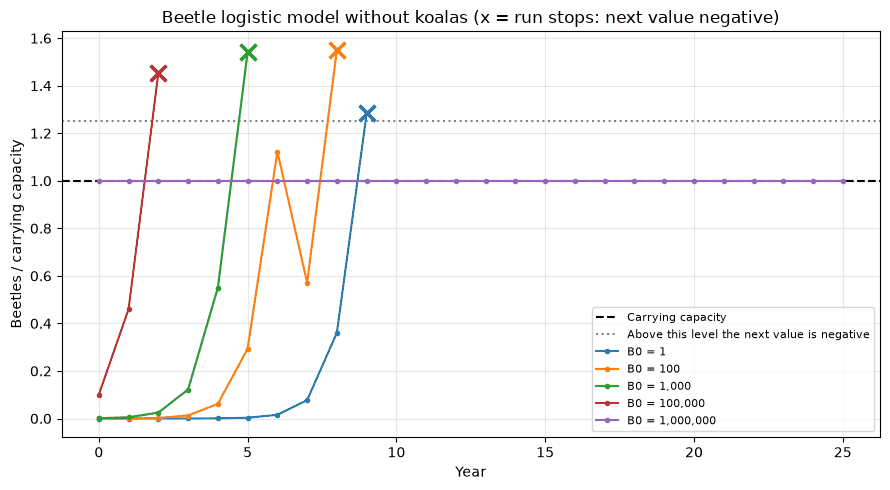

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(1, color="black", linestyle="--", label="Carrying capacity")
ax.axhline((1 + r_beetle) / r_beetle, color="gray", linestyle=":",
           label="Above this level the next value is negative")
for b0, (trajectory, invalid_year) in beetle_runs.items():
    line, = ax.plot(time_beetle, trajectory / K_beetle, marker="o", markersize=3,
                    label=f"B0 = {b0:,}")
    if invalid_year is not None:
        last = invalid_year - 1
        ax.plot(last, trajectory[last] / K_beetle, "x", color=line.get_color(),
                markersize=11, markeredgewidth=2.5)
ax.set(xlabel="Year", ylabel="Beetles / carrying capacity",
       title="Beetle logistic model without koalas (x = run stops: next value negative)")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Modeling note (beetles):** r_beetle = 4 comes from 10 offspring x 1/2 females = 5 young per beetle with every adult dying, so the net yearly factor is 5 = 1 + r. The update is applied exactly as specified in the assignment. For r = 4 it gives a negative next value whenever the population exceeds 1.25 K (dotted line), and the largest value the update can produce from a positive start is 1.5625 K. A simulation is therefore ended at its first negative value (marked x) rather than being clipped or continued.

## 2.6 Koala–beetle competition: equations and plan
Use each species' logistic equation with a competitor term, converting the competitor population into equivalent consumers of eucalyptus. What are the two conversion constants, and what are the two coupled update equations? Explain why the constants differ.

Plan the two-population arrays and simultaneous yearly update.

**Heuristic array and computation plan (zero-based indices):**

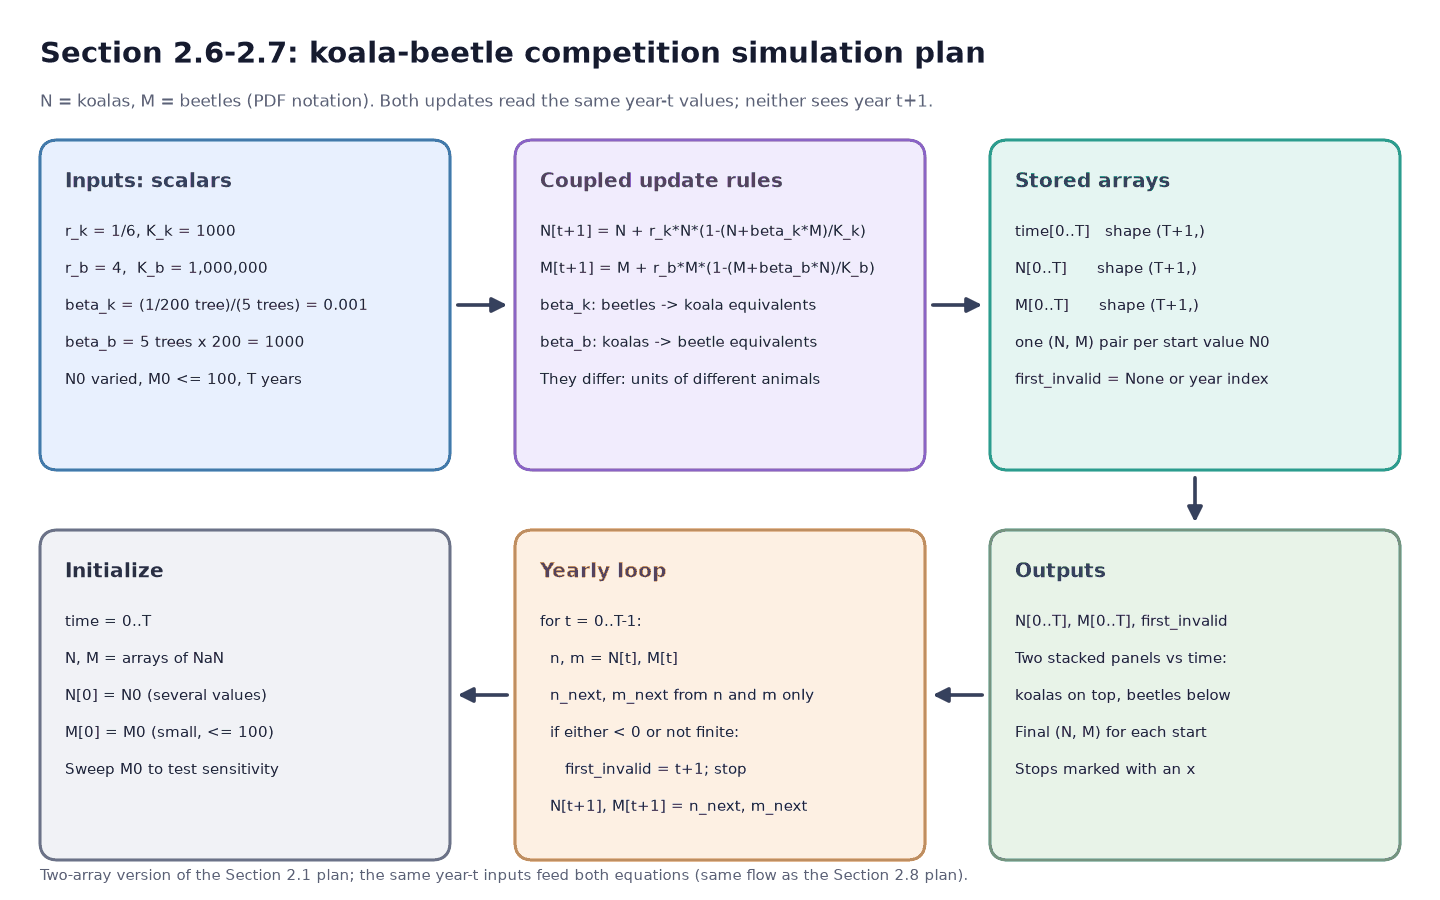

**Equations / plan:** A koala needs 5 trees and a beetle needs 1/200 of a tree, so one beetle uses (1/200)/5 = 1/1000 of a koala's food: **β_koala = 0.001** (beetles converted to koala equivalents). Conversely one koala uses as much food as 5 × 200 = 1000 beetles: **β_beetle = 1000** (koalas converted to beetle equivalents). The constants differ because each converts the competitor into the units of the species being analyzed, so they are reciprocals of each other. With N = koalas and M = beetles (r_koala = 1/6, K_koala = 1000, r_beetle = 4, K_beetle = 1,000,000):

N(t+1) = N(t) + (1/6)·N(t)·[1 − (N(t) + 0.001·M(t)) / 1000]

M(t+1) = M(t) + 4·M(t)·[1 − (M(t) + 1000·N(t)) / 1,000,000]

Both updates use only the year-t values (simultaneous update).

## 2.7 Competition outcomes
Introduce a small beetle population (initial beetles no more than 100) at year zero. Simulate a variety of initial koala populations. How many distinct long-run equilibria occur? Show the relevant trajectories and discuss the outcomes.

**Method:** coupled simulations and comparison plots.

In [13]:
# Convert beetle consumption to koala units and vice versa.
beta_koala = (1 / beetles_per_tree) / trees_per_koala
beta_beetle = trees_per_koala * beetles_per_tree

def simulate_competition(koalas_initial, beetles_initial, years):
    koalas = np.full(years + 1, np.nan)
    beetles = np.full(years + 1, np.nan)
    koalas[0], beetles[0] = koalas_initial, beetles_initial
    for t in range(years):
        k, b = koalas[t], beetles[t]
        # Simultaneous updates use only year-t values.
        k_next = k + r_koala * k * (1 - (k + beta_koala * b) / K_koala)
        b_next = b + r_beetle * b * (1 - (b + beta_beetle * k) / K_beetle)
        if not np.all(np.isfinite([k_next, b_next])) or min(k_next, b_next) < 0:
            return koalas, beetles, t + 1
        koalas[t + 1], beetles[t + 1] = k_next, b_next
    return koalas, beetles, None

years_competition = 60
time_competition = np.arange(years_competition + 1)
initial_koalas_competition = [100, 500, 1000, 1500]
initial_beetles_competition = 50  # Introduced at year 0; no more than 100.
competition_runs = {}
for k0 in initial_koalas_competition:
    koalas, beetles, invalid_year = simulate_competition(
        k0, initial_beetles_competition, years_competition)
    competition_runs[k0] = (koalas, beetles, invalid_year)
    print(f"Competition K0={k0}: first invalid year = {invalid_year}")
print(f"beta_koala = {beta_koala:g}; beta_beetle = {beta_beetle:g}")

# Sensitivity to the introduced beetle count (the PDF allows up to 100) and to the
# start. Runs that do not stop are followed for 2,000 years to see where they settle.
print("\nK0, B0: outcome (final koalas, final beetles, koalas + beta_koala * beetles)")
for k0 in [100, 300, 500, 800, 1000, 1200, 1500]:
    for b0 in [1, 10, 50, 100]:
        koalas, beetles, invalid_year = simulate_competition(k0, b0, 2000)
        if invalid_year is not None:
            print(f"K0={k0:5d}, B0={b0:3d}: stops in year {invalid_year}")
        else:
            print(f"K0={k0:5d}, B0={b0:3d}: koalas={koalas[-1]:8.1f}, beetles={beetles[-1]:11,.0f}, "
                  f"koalas + beta_koala*beetles = {koalas[-1] + beta_koala * beetles[-1]:8.1f}")

Competition K0=100: first invalid year = 12
Competition K0=500: first invalid year = None
Competition K0=1000: first invalid year = None
Competition K0=1500: first invalid year = 1
beta_koala = 0.001; beta_beetle = 1000

K0, B0: outcome (final koalas, final beetles, koalas + beta_koala * beetles)
K0=  100, B0=  1: koalas=   527.1, beetles=    472,868, koalas + beta_koala*beetles =   1000.0
K0=  100, B0= 10: koalas=   527.1, beetles=    472,868, koalas + beta_koala*beetles =   1000.0
K0=  100, B0= 50: stops in year 12
K0=  100, B0=100: stops in year 8
K0=  300, B0=  1: koalas=   740.5, beetles=    259,482, koalas + beta_koala*beetles =   1000.0
K0=  300, B0= 10: koalas=   651.7, beetles=    348,304, koalas + beta_koala*beetles =   1000.0
K0=  300, B0= 50: koalas=   590.9, beetles=    409,129, koalas + beta_koala*beetles =   1000.0
K0=  300, B0=100: koalas=   566.6, beetles=    433,440, koalas + beta_koala*beetles =   1000.0


K0=  500, B0=  1: koalas=   956.5, beetles=     43,540, koalas + beta_koala*beetles =   1000.0
K0=  500, B0= 10: koalas=   892.0, beetles=    107,960, koalas + beta_koala*beetles =   1000.0
K0=  500, B0= 50: koalas=   836.5, beetles=    163,523, koalas + beta_koala*beetles =   1000.0
K0=  500, B0=100: koalas=   811.0, beetles=    188,975, koalas + beta_koala*beetles =   1000.0
K0=  800, B0=  1: koalas=   999.9, beetles=         91, koalas + beta_koala*beetles =   1000.0
K0=  800, B0= 10: koalas=   999.1, beetles=        896, koalas + beta_koala*beetles =   1000.0
K0=  800, B0= 50: koalas=   995.8, beetles=      4,167, koalas + beta_koala*beetles =   1000.0
K0=  800, B0=100: koalas=   992.3, beetles=      7,704, koalas + beta_koala*beetles =   1000.0
K0= 1000, B0=  1: koalas=  1000.0, beetles=          1, koalas + beta_koala*beetles =   1000.0
K0= 1000, B0= 10: koalas=  1000.0, beetles=         10, koalas + beta_koala*beetles =   1000.0


K0= 1000, B0= 50: koalas=  1000.0, beetles=         50, koalas + beta_koala*beetles =   1000.0
K0= 1000, B0=100: koalas=   999.9, beetles=        100, koalas + beta_koala*beetles =   1000.0
K0= 1200, B0=  1: koalas=  1000.0, beetles=          0, koalas + beta_koala*beetles =   1000.0
K0= 1200, B0= 10: koalas=  1000.0, beetles=          0, koalas + beta_koala*beetles =   1000.0
K0= 1200, B0= 50: koalas=  1000.0, beetles=          0, koalas + beta_koala*beetles =   1000.0
K0= 1200, B0=100: koalas=  1000.0, beetles=          0, koalas + beta_koala*beetles =   1000.0
K0= 1500, B0=  1: stops in year 1
K0= 1500, B0= 10: stops in year 1
K0= 1500, B0= 50: stops in year 1
K0= 1500, B0=100: stops in year 1


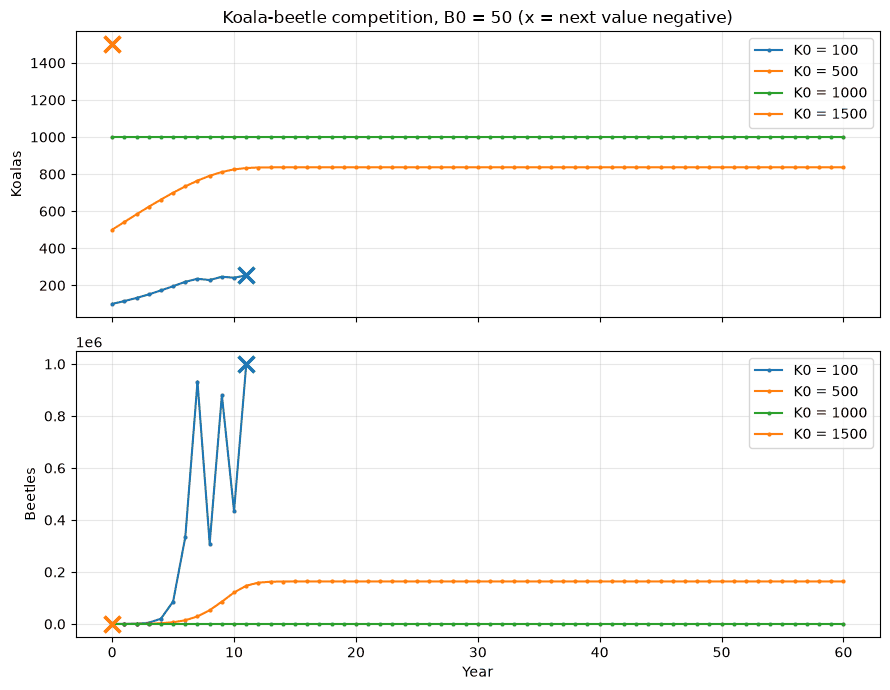

In [14]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for k0, (koalas, beetles, invalid_year) in competition_runs.items():
    line, = axes[0].plot(time_competition, koalas, marker="o", markersize=2,
                         label=f"K0 = {k0}")
    axes[1].plot(time_competition, beetles, marker="o", markersize=2,
                 color=line.get_color(), label=f"K0 = {k0}")
    if invalid_year is not None:
        last = invalid_year - 1
        for ax, series in ((axes[0], koalas), (axes[1], beetles)):
            ax.plot(last, series[last], "x", color=line.get_color(),
                    markersize=11, markeredgewidth=2.5)
axes[0].set(ylabel="Koalas",
            title="Koala-beetle competition, B0 = 50 (x = next value negative)")
axes[1].set(xlabel="Year", ylabel="Beetles")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Modeling note (competition):** beta_koala x beta_beetle = 1 and K_beetle = beta_beetle x K_koala, so the koala and beetle balance conditions describe the same line, koalas + beta_koala x beetles = K_koala. In the table above, every run that does not fail settles on that line, at a point that depends on its start. The failures come from the beetles' r = 4 overshoot: in the first year when K0 > 1250 (the koala load alone exceeds 1.25 K_beetle), or after a few oscillating years when beetle growth overshoots (K0 = 100 with B0 of 50 or more).

**Response (2.7):** *Setup:* 50 beetles (the assignment allows up to 100) are introduced at year 0 with koala starts of 100, 500, 1000 and 1500 in the plot; the table varies the start of both species. *Long-run equilibria:* there is not a small set of separate equilibria. Both species are limited only by the same 5,000 trees, and the conversion constants are exact reciprocals, so the two balance conditions are the same line, koalas + 0.001 × beetles = 1000, running from (1000 koalas, 0 beetles) to (0 koalas, 1,000,000 beetles). Every run that does not fail ends on that line, at a point set by its starting values: 836 koalas and 163,523 beetles from (500, 50); 591 koalas and 409,129 beetles from (300, 50); 996 koalas and 4,167 beetles from (800, 50); 1000 koalas and the starting beetles unchanged from (1000, B0); and 1000 koalas with beetles dying out from (1200, B0). So there are infinitely many equilibria, which fall into two kinds (koala-dominated with few or no beetles, and coexistence of both species), plus runs that fail. *Failures:* a start of 1500 koalas makes the beetle update negative in year 1 (the koala load is above 1.25 K_beetle), and a start of 100 koalas with 50 or more beetles fails after a few years of oscillation (years 12 and 8). These come from the beetles' large r (see 2.5) rather than from competition itself. If the conversion constants did not match the actual food use, the lines would not coincide and the usual outcomes of competition (one species excludes the other, or stable coexistence) would appear instead of this neutral line.


## 2.8 Koala–snake predator–prey model: equations and plan
Replace beetles with tree snakes. Each snake eats one koala per month. Modify the koala equation for annual predation. One-quarter of snakes are mature females, each reproducing successfully in a year with probability one-eighth; formulate the snake update analogous to the logistic equation, with snake carrying capacity depending on koala population. State any additional assumptions.

Plan the population arrays and yearly calculation flow.

**Array and computation plan:**

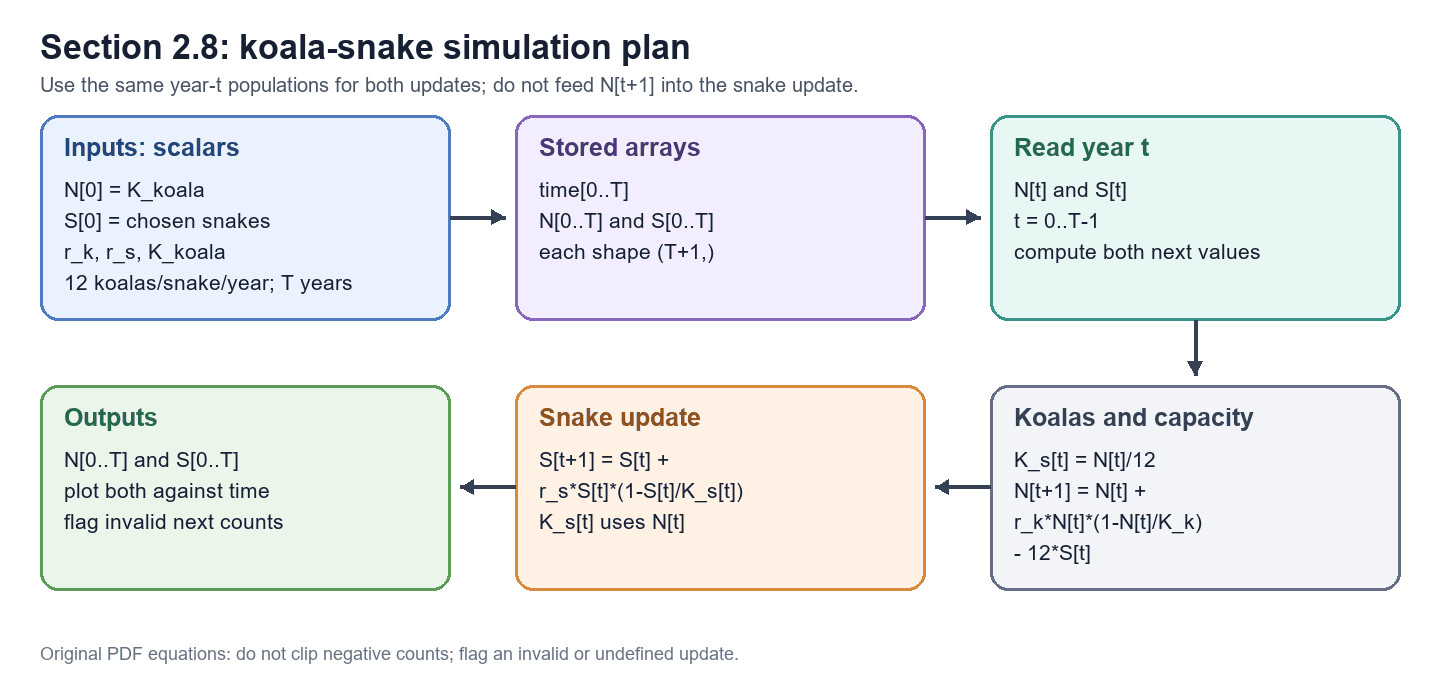

**Equations / plan:** One koala a month means 12 koalas per snake per year, taken without regard to age. With N = koalas, S = snakes, r_koala = 1/6, K_koala = 1000, and r_snake = (1/4)(1/8) = 1/32:

N(t+1) = N(t) + (1/6)·N(t)·[1 − N(t)/1000] − 12·S(t)

S(t+1) = S(t) + (1/32)·S(t)·[1 − S(t)/K_snakes(N(t))], with K_snakes(N) = N / 12

Both updates use the year-t values, and koalas start at N(0) = K_koala = 1000. *Additional assumptions:* K_snakes(N) = N/12 is the number of snakes the current koalas could feed for a year at 12 koalas each (the assignment only says it is a function of N); the snakes have no other food or mortality; and the equation is undefined when N = 0. Section 2.9c tests smaller capacities.

## 2.9 Predator–prey outcomes and thresholds
Start koalas at their carrying capacity. Vary the number of snakes introduced at year zero. How does the system respond? Are there introduction thresholds where a small change in initial snakes causes a large change in the long-run outcome? Plot and discuss the evidence.

**Method:** predator–prey simulations and plots.

In [15]:
female_snake_fraction = 1 / 4
snake_birth_probability = 1 / 8
r_snake = female_snake_fraction * snake_birth_probability
koalas_eaten_per_snake_year = 12

def simulate_predator_prey(snakes_initial, years):
    koalas = np.full(years + 1, np.nan)
    snakes = np.full(years + 1, np.nan)
    koalas[0], snakes[0] = K_koala, snakes_initial
    for t in range(years):
        k, s = koalas[t], snakes[t]
        snake_capacity = k / koalas_eaten_per_snake_year
        if snake_capacity == 0 and s > 0:
            return koalas, snakes, t + 1  # Snake equation is undefined.
        k_next = k + r_koala * k * (1 - k / K_koala) - 12 * s
        s_next = (s + r_snake * s * (1 - s / snake_capacity)
                  if snake_capacity > 0 else 0.0)
        if not np.all(np.isfinite([k_next, s_next])) or min(k_next, s_next) < 0:
            return koalas, snakes, t + 1
        koalas[t + 1], snakes[t + 1] = k_next, s_next
    return koalas, snakes, None

years_predator = 150
time_predator = np.arange(years_predator + 1)
initial_snakes = [0, 1, 2, 5, 10, 20, 40, 80]
predator_runs = {}
for s0 in initial_snakes:
    koalas, snakes, invalid_year = simulate_predator_prey(s0, years_predator)
    predator_runs[s0] = (koalas, snakes, invalid_year)
    print(f"Predator-prey S0={s0}: first invalid year = {invalid_year}")

# Scan introductions one snake at a time. Outcome = does the koala update ever go
# negative within 150 years, and if so when (time to collapse).
snake_grid = np.arange(0, 101)
first_invalid = [
    simulate_predator_prey(int(s0), years_predator)[2] for s0 in snake_grid
]
survivors = [int(s) for s, y in zip(snake_grid, first_invalid) if y is None]
collapse = [(int(s), y) for s, y in zip(snake_grid, first_invalid) if y is not None]
print(f"Introductions with no invalid update in {years_predator} years: S0 = {survivors}")
print(f"Introductions that collapse: {len(collapse)} of {len(snake_grid)}; "
      f"first invalid year for S0 = 1..5: {[y for _, y in collapse[:5]]}")
max_harvest = r_koala * K_koala / 4
print(f"Largest steady annual kill the koala growth term can replace: r*K/4 = "
      f"{max_harvest:.1f} koalas/year = {max_harvest / koalas_eaten_per_snake_year:.2f} snakes")

Predator-prey S0=0: first invalid year = None
Predator-prey S0=1: first invalid year = 70
Predator-prey S0=2: first invalid year = 47
Predator-prey S0=5: first invalid year = 21
Predator-prey S0=10: first invalid year = 10
Predator-prey S0=20: first invalid year = 5
Predator-prey S0=40: first invalid year = 3
Predator-prey S0=80: first invalid year = 2
Introductions with no invalid update in 150 years: S0 = [0]
Introductions that collapse: 100 of 101; first invalid year for S0 = 1..5: [70, 47, 34, 26, 21]
Largest steady annual kill the koala growth term can replace: r*K/4 = 41.7 koalas/year = 3.47 snakes


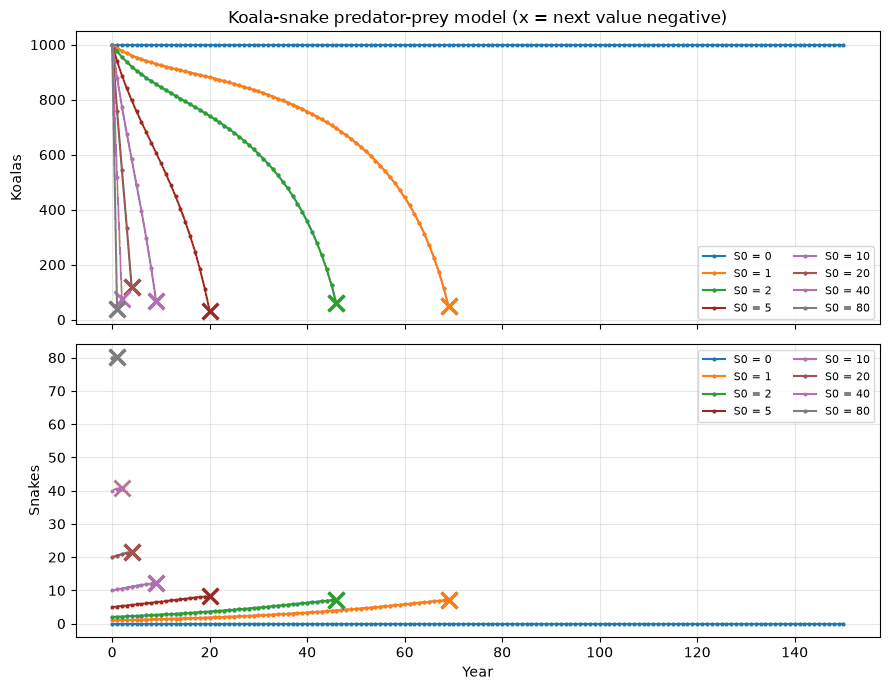

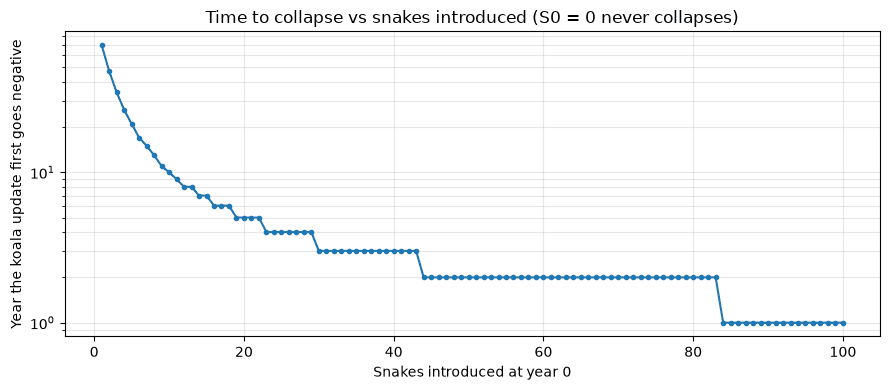

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
for s0, (koalas, snakes, invalid_year) in predator_runs.items():
    line, = axes[0].plot(time_predator, koalas, marker="o", markersize=2,
                         label=f"S0 = {s0}")
    axes[1].plot(time_predator, snakes, marker="o", markersize=2,
                 color=line.get_color(), label=f"S0 = {s0}")
    if invalid_year is not None:
        last = invalid_year - 1
        for ax, series in ((axes[0], koalas), (axes[1], snakes)):
            ax.plot(last, series[last], "x", color=line.get_color(),
                    markersize=11, markeredgewidth=2.5)
axes[0].set(ylabel="Koalas",
            title="Koala-snake predator-prey model (x = next value negative)")
axes[1].set(xlabel="Year", ylabel="Snakes")
for ax in axes:
    ax.legend(ncol=2, fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy([s for s, _ in collapse], [y for _, y in collapse], ".-")
ax.set(xlabel="Snakes introduced at year 0",
       ylabel="Year the koala update first goes negative",
       title="Time to collapse vs snakes introduced (S0 = 0 never collapses)")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

**Modeling assumption (predator-prey):** the assignment only says K_snakes is a function of N_t. This analysis uses K_snakes(N_t) = N_t / 12, the number of snakes the current koalas could feed at 12 koalas per snake-year; koalas eaten use the same year-t snake count (S_t) as the assignment states. At that capacity the snakes would eat the entire koala population each year, which shapes the collapse results above. A different capacity function would change them; Section 2.9c repeats the scan with smaller capacities.

### 2.9a Zero-floor sensitivity (modified model)
This comparison is separate from the original simulations above, which are unchanged. After each exact annual update, replace a negative population with zero. Apply the rule to beetles alone, both species in competition, and koalas and snakes in predator-prey runs. If koalas are already zero, set next year's snake population to zero because the snake carrying-capacity expression would otherwise divide by zero. These are added boundary rules, not part of the specified model.


In [17]:
def simulate_logistic_floor(initial, rate, capacity, years):
    values = np.empty(years + 1)
    values[0] = initial
    for t in range(years):
        n = values[t]
        raw_next = n + rate * n * (1 - n / capacity)
        values[t + 1] = max(0.0, raw_next)
    return values

def simulate_competition_floor(koalas_initial, beetles_initial, years):
    koalas = np.empty(years + 1)
    beetles = np.empty(years + 1)
    koalas[0], beetles[0] = koalas_initial, beetles_initial
    for t in range(years):
        k, b = koalas[t], beetles[t]
        k_raw = k + r_koala * k * (1 - (k + beta_koala * b) / K_koala)
        b_raw = b + r_beetle * b * (1 - (b + beta_beetle * k) / K_beetle)
        koalas[t + 1] = max(0.0, k_raw)
        beetles[t + 1] = max(0.0, b_raw)
    return koalas, beetles

def simulate_predator_prey_floor(snakes_initial, years):
    koalas = np.empty(years + 1)
    snakes = np.empty(years + 1)
    koalas[0], snakes[0] = K_koala, snakes_initial
    for t in range(years):
        k, s = koalas[t], snakes[t]
        k_raw = k + r_koala * k * (1 - k / K_koala) - 12 * s
        snake_capacity = k / koalas_eaten_per_snake_year
        s_raw = (s + r_snake * s * (1 - s / snake_capacity)
                 if snake_capacity > 0 else 0.0)
        koalas[t + 1] = max(0.0, k_raw)
        snakes[t + 1] = max(0.0, s_raw)
    return koalas, snakes

comparison_years = 25
comparison_time = np.arange(comparison_years + 1)
beetles_original, _ = simulate_logistic(100_000, r_beetle, K_beetle, comparison_years)
beetles_floor = simulate_logistic_floor(100_000, r_beetle, K_beetle, comparison_years)
koalas_original, beetles_comp_original, _ = simulate_competition(100, 50, comparison_years)
koalas_floor, beetles_comp_floor = simulate_competition_floor(100, 50, comparison_years)
koalas_pred_original, snakes_pred_original, _ = simulate_predator_prey(10, comparison_years)
koalas_pred_floor, snakes_pred_floor = simulate_predator_prey_floor(10, comparison_years)

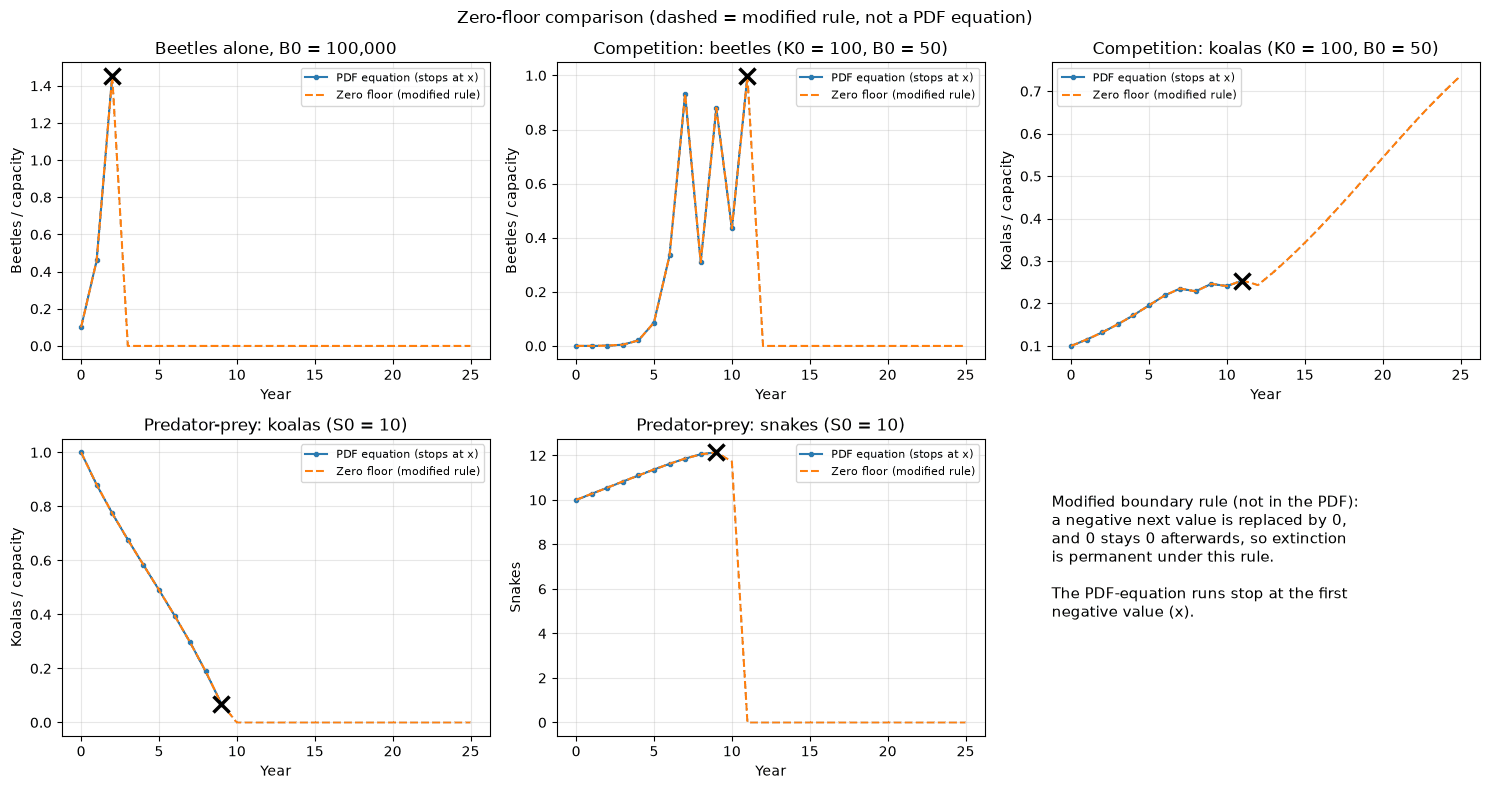

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

def compare(ax, original, floored, scale, title, ylabel):
    """Original PDF run (stops at x) against the zero-floor run (dashed, modified)."""
    ax.plot(comparison_time, original / scale, marker="o", markersize=3,
            label="PDF equation (stops at x)")
    ax.plot(comparison_time, floored / scale, "--", label="Zero floor (modified rule)")
    valid = np.flatnonzero(~np.isnan(original))
    if valid[-1] < len(original) - 1:
        ax.plot(valid[-1], original[valid[-1]] / scale, "x", color="black",
                markersize=11, markeredgewidth=2.5)
    ax.set(title=title, ylabel=ylabel, xlabel="Year")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

compare(axes[0, 0], beetles_original, beetles_floor, K_beetle,
        "Beetles alone, B0 = 100,000", "Beetles / capacity")
compare(axes[0, 1], beetles_comp_original, beetles_comp_floor, K_beetle,
        "Competition: beetles (K0 = 100, B0 = 50)", "Beetles / capacity")
compare(axes[0, 2], koalas_original, koalas_floor, K_koala,
        "Competition: koalas (K0 = 100, B0 = 50)", "Koalas / capacity")
compare(axes[1, 0], koalas_pred_original, koalas_pred_floor, K_koala,
        "Predator-prey: koalas (S0 = 10)", "Koalas / capacity")
compare(axes[1, 1], snakes_pred_original, snakes_pred_floor, 1,
        "Predator-prey: snakes (S0 = 10)", "Snakes")
axes[1, 2].axis("off")
axes[1, 2].text(0.0, 0.6,
                "Modified boundary rule (not in the PDF):\n"
                "a negative next value is replaced by 0,\n"
                "and 0 stays 0 afterwards, so extinction\n"
                "is permanent under this rule.\n\n"
                "The PDF-equation runs stop at the first\n"
                "negative value (x).",
                fontsize=11, va="center")
fig.suptitle("Zero-floor comparison (dashed = modified rule, not a PDF equation)")
plt.tight_layout()
plt.show()

### 2.9b Limited-kills sensitivity (modified predator-prey model)
Keep the original predator-prey equations above for comparison. Here the annual kill count is the smaller of 12 times the current snake population and the koalas available after that year's logistic growth. This changes only the predation term while prey remain positive. If prey have reached zero, set next year's snakes to zero because their carrying capacity is zero. The snake update otherwise remains unchanged; the simulation still ends if that update becomes negative. For nonnegative available koalas, both fixes yield the same next koala count; limited kills additionally records how many koalas were actually eaten. The third comparison plot shows requested versus actual kills.


In [19]:
def simulate_predator_prey_limited_kills(snakes_initial, years):
    koalas = np.full(years + 1, np.nan)
    snakes = np.full(years + 1, np.nan)
    kills = np.full(years, np.nan)
    koalas[0], snakes[0] = K_koala, snakes_initial
    for t in range(years):
        k, s = koalas[t], snakes[t]
        available = k + r_koala * k * (1 - k / K_koala)
        if available < 0:
            return koalas, snakes, kills, t + 1
        kills[t] = min(12 * s, available)
        k_next = available - kills[t]
        snake_capacity = k / koalas_eaten_per_snake_year
        s_next = (s + r_snake * s * (1 - s / snake_capacity)
                  if snake_capacity > 0 else 0.0)
        if not np.isfinite(s_next) or s_next < 0:
            return koalas, snakes, kills, t + 1
        koalas[t + 1], snakes[t + 1] = k_next, s_next
    return koalas, snakes, kills, None

limited_years = 30
limited_time = np.arange(limited_years + 1)
snakes_initial_comparison = 10
k_original, s_original, original_invalid = simulate_predator_prey(
    snakes_initial_comparison, limited_years)
k_floor, s_floor = simulate_predator_prey_floor(
    snakes_initial_comparison, limited_years)
k_limited, s_limited, actual_kills, limited_invalid = (
    simulate_predator_prey_limited_kills(snakes_initial_comparison, limited_years))
capped_years = np.flatnonzero(actual_kills < 12 * s_limited[:-1] - 1e-9)
print(f"PDF equation first invalid year: {original_invalid}")
print(f"Limited-kills first invalid year: {limited_invalid}")
print(f"Years when kills were capped: {capped_years.tolist()}")

# Consistency of the two modified rules over every introduction from 0 to 100 snakes.
agree, stopped = 0, []
for s0 in range(101):
    kf, sf = simulate_predator_prey_floor(s0, limited_years)
    kl, sl, _, invalid = simulate_predator_prey_limited_kills(s0, limited_years)
    if invalid is not None:
        stopped.append((s0, invalid))
    elif np.allclose(kf, kl) and np.allclose(sf, sl):
        agree += 1
print(f"Zero floor and limited kills give identical koala and snake paths for {agree} of "
      f"{101 - len(stopped)} introductions where limited kills completes.")
print(f"Limited kills stops (snake update negative) for (S0, year): {stopped}")

PDF equation first invalid year: 10
Limited-kills first invalid year: None
Years when kills were capped: [9, 10]
Zero floor and limited kills give identical koala and snake paths for 97 of 97 introductions where limited kills completes.
Limited kills stops (snake update negative) for (S0, year): [(43, 3), (81, 2), (82, 2), (83, 2)]


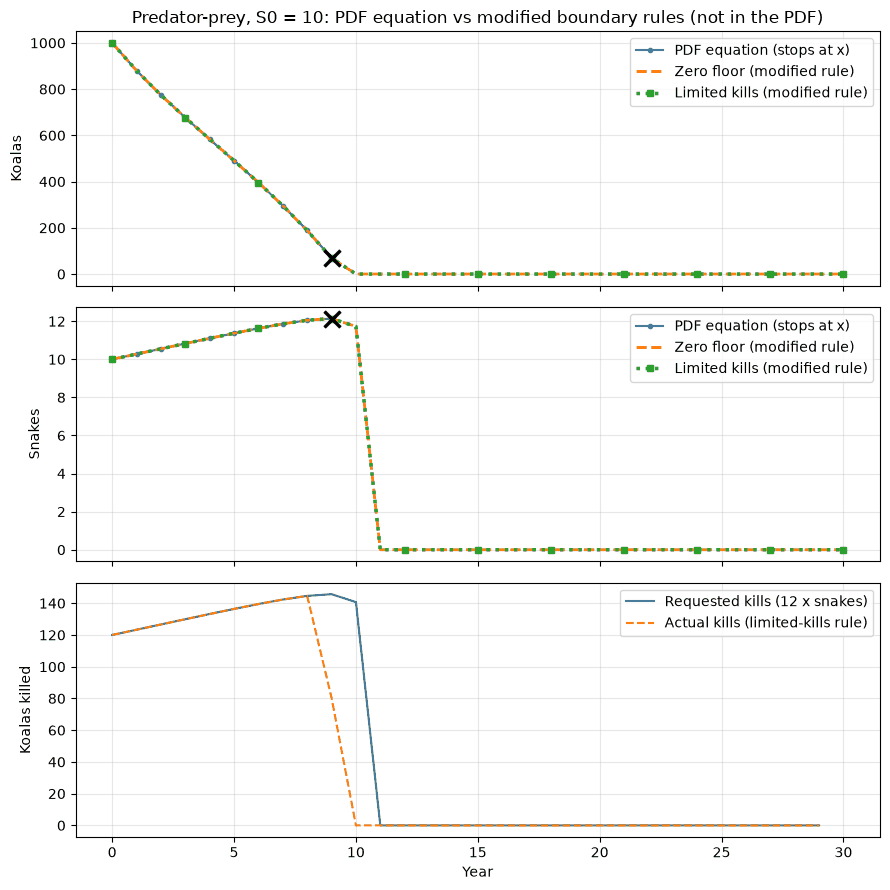

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(9, 9), sharex=True)
for ax, original, floor, limited, label in (
    (axes[0], k_original, k_floor, k_limited, "Koalas"),
    (axes[1], s_original, s_floor, s_limited, "Snakes"),
):
    ax.plot(limited_time, original, marker="o", markersize=3, label="PDF equation (stops at x)")
    ax.plot(limited_time, floor, "--", linewidth=2, label="Zero floor (modified rule)")
    ax.plot(limited_time, limited, ":", linewidth=2.5, marker="s", markersize=4,
            markevery=3, label="Limited kills (modified rule)")
    valid = np.flatnonzero(~np.isnan(original))
    if valid[-1] < len(original) - 1:
        ax.plot(valid[-1], original[valid[-1]], "x", color="black",
                markersize=11, markeredgewidth=2.5)
    ax.set_ylabel(label)
    ax.legend()
    ax.grid(alpha=0.3)
axes[0].set_title("Predator-prey, S0 = 10: PDF equation vs modified boundary rules "
                  "(not in the PDF)")
axes[2].plot(limited_time[:-1], 12 * s_limited[:-1], label="Requested kills (12 x snakes)")
axes[2].plot(limited_time[:-1], actual_kills, "--", label="Actual kills (limited-kills rule)")
axes[2].set_ylabel("Koalas killed")
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_xlabel("Year")
plt.tight_layout()
plt.show()

### 2.9c Snake carrying-capacity sensitivity (modified model)
The assignment only says that K_snakes is a function of N_t. The analysis above uses K_snakes(N) = N / 12. This optional comparison scales that capacity: K_snakes(N) = f x N / 12, where f is the share of the koala stock the snakes could eat in a year if they were at capacity (f = 1 is the original model). Every other equation is unchanged and the specified update is applied exactly: a simulation ends at its first negative or undefined value, which is counted as collapse. This is a modified model, not part of the specified model.


In [21]:
def simulate_predator_prey_capacity(snakes_initial, capacity_fraction, years):
    """PDF predator-prey update with K_snakes(N) = capacity_fraction * N / 12."""
    koalas = np.full(years + 1, np.nan)
    snakes = np.full(years + 1, np.nan)
    koalas[0], snakes[0] = K_koala, snakes_initial
    for t in range(years):
        k, s = koalas[t], snakes[t]
        snake_capacity = capacity_fraction * k / koalas_eaten_per_snake_year
        k_next = k + r_koala * k * (1 - k / K_koala) - 12 * s
        s_next = (s + r_snake * s * (1 - s / snake_capacity)
                  if snake_capacity > 0 else 0.0)
        if not np.all(np.isfinite([k_next, s_next])) or min(k_next, s_next) < 0:
            return koalas, snakes, t + 1
        koalas[t + 1], snakes[t + 1] = k_next, s_next
    return koalas, snakes, None

capacity_fractions = [1, 0.5, 0.1, 0.09, 0.07, 0.05, 0.04, 0.03, 0.02]
capacity_years = 1500
introductions = np.arange(0, 101)
def collapse_reason(koalas, snakes, invalid_year):
    """Which update went negative in the first invalid year."""
    k, s = koalas[invalid_year - 1], snakes[invalid_year - 1]
    k_next = k + r_koala * k * (1 - k / K_koala) - 12 * s
    return "koala" if k_next < 0 else "snake"

capacity_outcomes = {}
print("f: introductions that avoid collapse | first collapse | lowest koala count of the largest safe introduction | predicted coexistence (koalas / snakes) | end state from S0 = 1")
for f in capacity_fractions:
    runs = [simulate_predator_prey_capacity(int(s0), f, capacity_years) for s0 in introductions]
    survives = np.array([run[2] is None for run in runs])
    capacity_outcomes[f] = np.array([run[0][-1] / K_koala if ok else 0.0
                                     for run, ok in zip(runs, survives)])
    safe = introductions[survives]
    contiguous = safe.size > 0 and np.array_equal(safe, np.arange(safe.size))
    safe_text = (f"S0 = 0..{safe.max()}" if contiguous else f"S0 = {safe.tolist()}")
    first_bad = int(introductions[~survives][0])
    bad_k, bad_s, bad_year = runs[first_bad]
    lowest = np.nanmin(runs[int(safe.max())][0])
    if f < r_koala:  # a positive coexistence point exists only when f < r_koala
        koalas_star = K_koala * (1 - f / r_koala)
        coexist = f"{koalas_star:.0f} / {f * koalas_star / koalas_eaten_per_snake_year:.2f}"
    else:
        coexist = "none"
    koalas_1, snakes_1, invalid_1 = runs[1]
    end_1 = (f"collapses in year {invalid_1}" if invalid_1 is not None
             else f"{koalas_1[-1]:.0f} koalas / {snakes_1[-1]:.2f} snakes")
    print(f"f = {f:g}: {safe_text} | S0 = {first_bad}, year {bad_year}, "
          f"{collapse_reason(bad_k, bad_s, bad_year)} update | lowest koalas {lowest:.1f} | "
          f"{coexist} | {end_1}")

# Tipping example for f = 0.05: the last safe introduction and the first that collapses.
tipping_runs = {s0: simulate_predator_prey_capacity(s0, 0.05, 150) for s0 in (16, 17)}

f: introductions that avoid collapse | first collapse | lowest koala count of the largest safe introduction | predicted coexistence (koalas / snakes) | end state from S0 = 1
f = 1: S0 = 0..0 | S0 = 1, year 70, koala update | lowest koalas 1000.0 | none | collapses in year 70
f = 0.5: S0 = 0..0 | S0 = 1, year 73, koala update | lowest koalas 1000.0 | none | collapses in year 73
f = 0.1: S0 = 0..0 | S0 = 1, year 148, koala update | lowest koalas 1000.0 | 400 / 3.33 | collapses in year 148
f = 0.09: S0 = 0..4 | S0 = 5, year 57, koala update | lowest koalas 244.0 | 460 / 3.45 | 460 koalas / 3.45 snakes
f = 0.07: S0 = 0..7 | S0 = 8, year 51, koala update | lowest koalas 190.9 | 580 / 3.38 | 580 koalas / 3.38 snakes


f = 0.05: S0 = 0..16 | S0 = 17, year 24, koala update | lowest koalas 4.2 | 700 / 2.92 | 700 koalas / 2.92 snakes


f = 0.04: S0 = 0..33 | S0 = 34, year 14, koala update | lowest koalas 0.0 | 760 / 2.53 | 760 koalas / 2.53 snakes


f = 0.03: S0 = 0..82 | S0 = 83, year 1, snake update | lowest koalas 9.0 | 820 / 2.05 | 820 koalas / 2.05 snakes


f = 0.02: S0 = 0..55 | S0 = 56, year 1, snake update | lowest koalas 340.0 | 880 / 1.47 | 880 koalas / 1.47 snakes


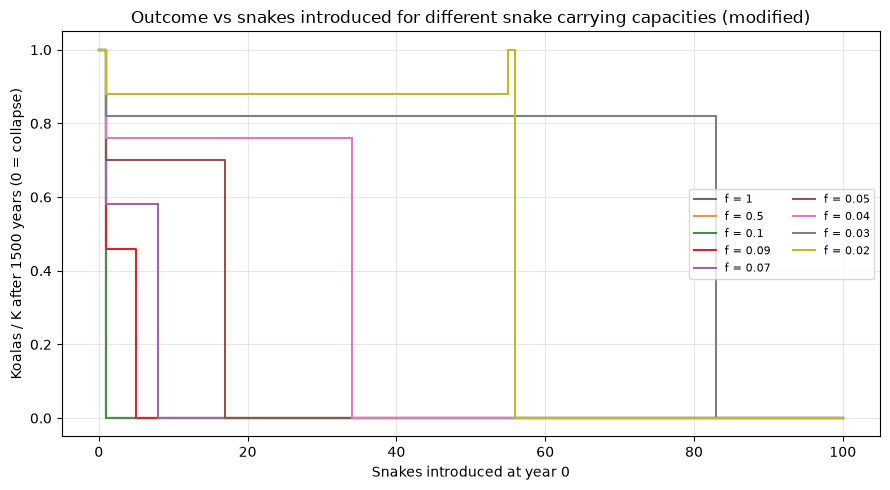

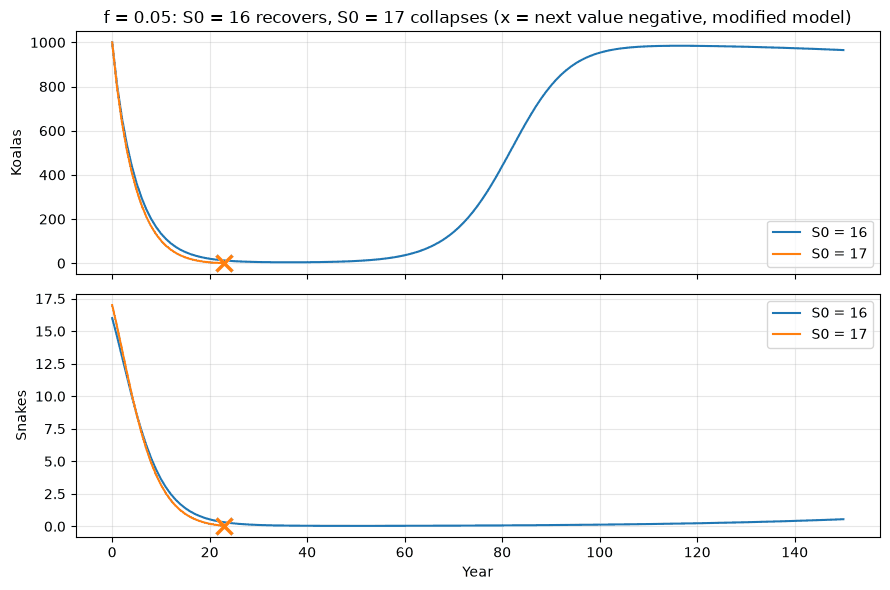

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))
for f, final_koalas in capacity_outcomes.items():
    ax.plot(introductions, final_koalas, drawstyle="steps-post", label=f"f = {f:g}")
ax.set(xlabel="Snakes introduced at year 0",
       ylabel=f"Koalas / K after {capacity_years} years (0 = collapse)",
       title="Outcome vs snakes introduced for different snake carrying capacities (modified)")
ax.legend(ncol=2, fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for s0, (koalas, snakes, invalid_year) in tipping_runs.items():
    line, = axes[0].plot(np.arange(151), koalas, label=f"S0 = {s0}")
    axes[1].plot(np.arange(151), snakes, color=line.get_color(), label=f"S0 = {s0}")
    if invalid_year is not None:
        last = invalid_year - 1
        for ax_, series in ((axes[0], koalas), (axes[1], snakes)):
            ax_.plot(last, series[last], "x", color=line.get_color(),
                     markersize=11, markeredgewidth=2.5)
axes[0].set(ylabel="Koalas", title="f = 0.05: S0 = 16 recovers, S0 = 17 collapses "
                                    "(x = next value negative, modified model)")
axes[1].set(xlabel="Year", ylabel="Snakes")
for ax_ in axes:
    ax_.legend()
    ax_.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Response (2.9c):** *Departure from the baseline model.* The baseline analysis set the snake capacity to N/12 (f = 1), so snakes at capacity would eat every koala each year. No snake population can then coexist with the koalas, and every introduction collapsed. Here the capacity is a fraction f of that. The assignment does not specify the function, so the results below depend on this modeling choice. *Findings* (1,500-year runs, 0 to 100 snakes introduced):
- **f = 1, 0.5 and 0.1:** only S0 = 0 avoids collapse. At f = 0.1 a coexistence point exists (400 koalas, 3.3 snakes), but the snakes grow past what the koalas can feed (about 3.5 snakes) before the koalas adjust, and the koala dip that follows is too deep to recover from.
- **f = 0.09 down to 0.04: a real threshold in S0.** Small introductions settle on a stable coexistence point with K(1 − f/r) koalas and f·N/12 snakes (for example 700 koalas and 2.9 snakes at f = 0.05, as the formulas predict), and larger introductions collapse the koalas years later. The largest safe introduction is 4 snakes at f = 0.09, 7 at f = 0.07, 16 at f = 0.05 and 33 at f = 0.04, so a smaller capacity moves the threshold to more snakes. At f = 0.09 and 0.07 the koalas dip to 244 and 191 before recovering. At f = 0.05 the safe introduction of 16 snakes drives the koalas down to about 4, and at f = 0.04 the safe 33 snakes drive them to well under one animal, before they recover; those two thresholds depend on a population that a real koala population would not survive, so only the f = 0.09 and 0.07 cases are realistic tipping points.
- **f = 0.03 and 0.02:** the cut-offs (S0 = 83 and 56) are not tipping points. The snake update itself goes negative in year 1 because the introduced snakes exceed about 33 times the capacity, the same overshoot limit of the discrete logistic as in 2.5.
- **The tipping example (second plot, f = 0.05):** S0 = 16 and S0 = 17 follow almost the same path for 20 years. With 16 the koalas bottom out near 4 and recover to near 1000 (then drift toward 700), while with 17 the koala update goes negative in year 24, so a one-snake difference decides between recovery and collapse.


**Response (2.9):** *Original model (K_snakes = N/12).* With no snakes, koalas stay at K = 1000. For every introduction from 1 to 100 snakes the koala population is driven to zero: the koala update first goes negative in year 70 for 1 snake, 47 for 2, 34 for 3, 21 for 5, 10 for 10, 5 for 20, 3 for 40, 2 for 80, and in year 1 for 84 or more (12 × 84 exceeds 1000). While this happens the snakes grow (10 introduced reach about 12) and then crash once the koalas are gone. The cause is that koalas can replace at most r·K/4 ≈ 41.7 koalas a year, which feeds about 3.5 snakes, while snakes keep growing toward N/12, a capacity they cannot sustain, so even one snake eventually removes the koalas. Under this reading there is **no threshold** in S0 between survival and collapse: the only change in outcome is between 0 snakes and any snakes, and a small change in S0 changes only how soon the collapse occurs (70 years for one snake versus 47 for two). The modified rules in 2.9a and 2.9b give the same result, since the zero floor and limited kills produce identical koala and snake paths for all 97 introductions for which the limited-kills version completes.

*Sensitivity to the snake carrying capacity (2.9c).* The absence of a threshold comes from the assumption K_snakes = N/12. If the snakes' capacity is a smaller fraction f of that (f ≤ 0.09), there is a threshold: introductions up to 4 snakes (f = 0.09), 7 (f = 0.07), 16 (f = 0.05) or 33 (f = 0.04) settle on a stable coexistence with the koalas, and one more snake makes the koalas collapse. So the answer to "are there thresholds?" is no under the capacity first used and yes under a capacity that does not let the snakes consume the whole koala stock, where a change of a single snake near the threshold decides between recovery and collapse. The threshold values depend on f and are not determined by the assignment.


## 2.10 Don’t compute, just think
Would an introduced snake prefer beetles to be introduced? Would a beetle prefer snakes to be introduced? Discuss both questions briefly, using the food-web relationships rather than another computation.

**Response:** *A snake would not want beetles introduced.* Beetles compete with koalas for eucalyptus leaves, which shrinks the koala population, the snakes' only food. In the competition runs the koalas settled below 1000 once beetles arrived (for example at 836 from a start of 500). *A beetle would want snakes introduced.* Snakes eat koalas, the beetles' competitor, so fewer koalas leaves more leaves for the beetles. In the competition model the food load on the beetles falls as koalas decline, so their effective capacity rises. The relationship is one-way: beetles help snakes only by being absent, and snakes help beetles by removing koalas, until the snakes run out of koalas and die out too.

# 3. Tracking snow leopards
## 3.1 Movement model: design and short check
Model a 10 × 10 grid with daily steps. A leopard must move to one of the adjacent eight cells that remains inside the habitat, choosing uniformly among available cells. Plan position and time storage, boundary handling, random movement, and reusable functions; include a diagram of dimensions, indices, and decision order. Test each part separately.

Run and inspect a single leopard for fewer than ten steps, then produce the requested ten-day script output.

**Heuristic plan: dimensions, indices, functions and order of decisions:**

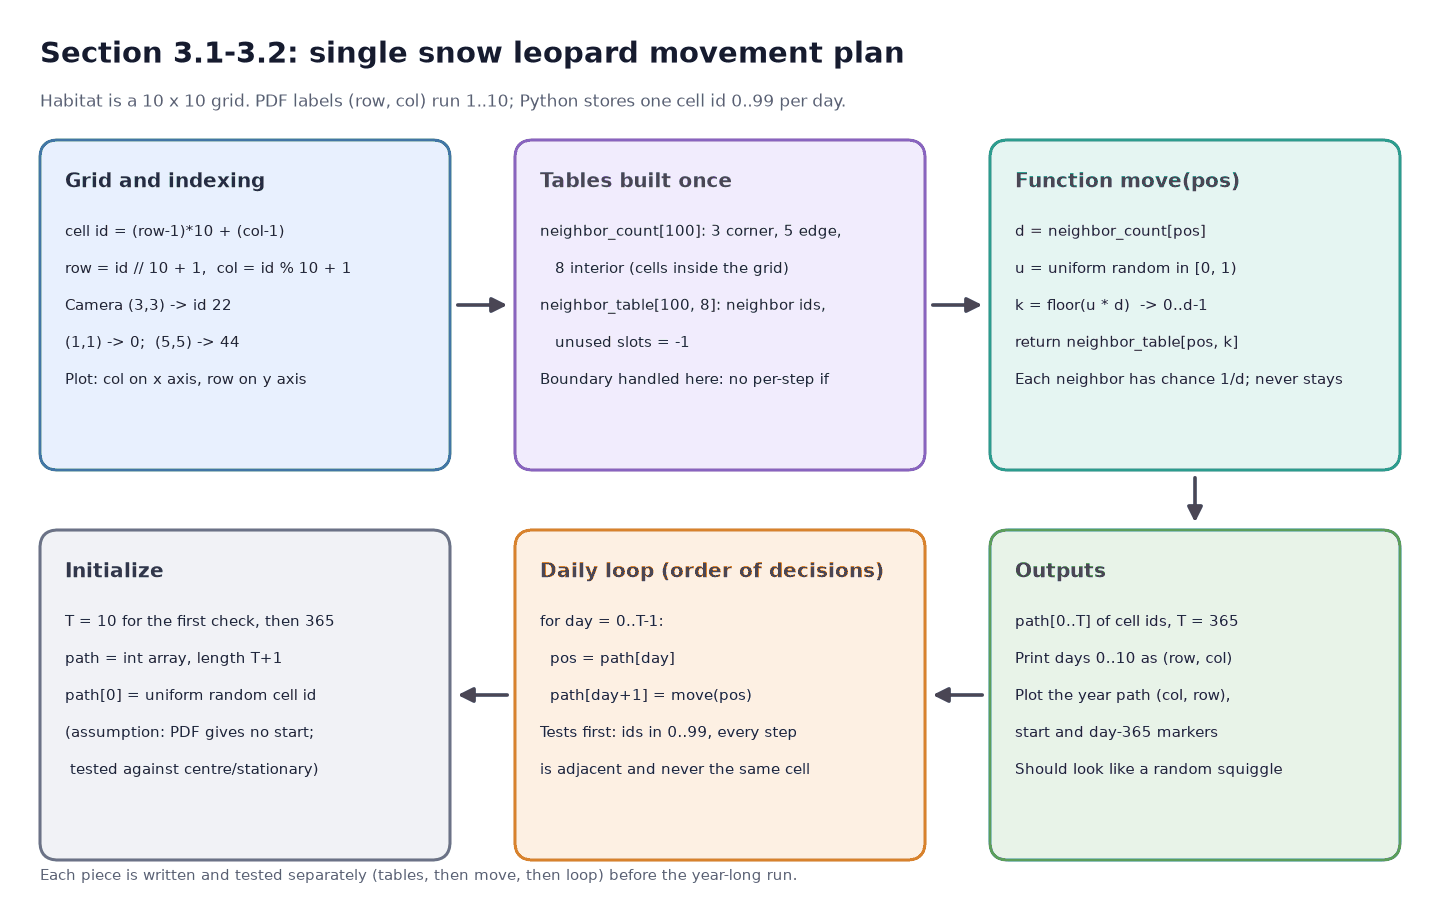

**Plan:** The habitat is a 10 × 10 grid whose 100 cells are numbered 0 to 99, so a leopard's position is a single integer. For every cell the list of adjacent habitat cells is prepared in advance: 3 for corner cells, 5 for edge cells and 8 for interior cells, so the habitat boundary is handled by construction. Each day the leopard moves to one of its available neighbors chosen with equal probability (1/3, 1/5 or 1/8), so it never stays in the same cell, and its position on every day is recorded in an array of length days + 1. The model was validated piece by piece: the neighbor counts of a corner, an edge and an interior cell, the neighbors of cell 0, and, over a 10-day run, that every move goes to an adjacent cell and never to the same cell. A 10-day run is followed by the 365-day run. The diagram above gives the array dimensions, indices and order of decisions.

**Method:** single-leopard movement and short-run checks.

In [23]:
import numpy as np
import matplotlib.pyplot as plt

GRID_SIZE = 10
neighbor_table = np.full((GRID_SIZE**2, 8), -1, dtype=np.int16)
neighbor_count = np.zeros(GRID_SIZE**2, dtype=np.int8)
for row in range(GRID_SIZE):
    for col in range(GRID_SIZE):
        cell = row * GRID_SIZE + col
        options = [
            (row + dr) * GRID_SIZE + (col + dc)
            for dr in (-1, 0, 1) for dc in (-1, 0, 1)
            if (dr, dc) != (0, 0)
            and 0 <= row + dr < GRID_SIZE
            and 0 <= col + dc < GRID_SIZE
        ]
        neighbor_count[cell] = len(options)
        neighbor_table[cell, :len(options)] = options

def move_positions(positions, rng):
    # Works for one cell or an array of independent animal positions.
    degrees = neighbor_count[positions]
    choices = (rng.random(np.shape(positions)) * degrees).astype(int)
    return neighbor_table[positions, choices]

assert set(neighbor_table[0, :neighbor_count[0]]) == {1, 10, 11}
assert neighbor_count[0] == 3 and neighbor_count[5] == 5
assert neighbor_count[55] == 8
short_rng = np.random.default_rng(42)
short_path = np.empty(11, dtype=np.int16)  # Day 0 plus ten daily moves.
# Initial position is uniform over the 100 habitat cells.
short_path[0] = short_rng.integers(GRID_SIZE**2)
for day in range(10):
    short_path[day + 1] = move_positions(short_path[day], short_rng)
assert np.all(short_path[1:] != short_path[:-1])
assert all(next_cell in neighbor_table[cell, :neighbor_count[cell]]
           for cell, next_cell in zip(short_path[:-1], short_path[1:]))
print("day, MATLAB-style row, MATLAB-style column")
print(np.column_stack((np.arange(11), short_path // GRID_SIZE + 1,
                       short_path % GRID_SIZE + 1)))


day, MATLAB-style row, MATLAB-style column
[[ 0  1  9]
 [ 1  2  8]
 [ 2  3  8]
 [ 3  4  7]
 [ 4  3  6]
 [ 5  4  7]
 [ 6  5  7]
 [ 7  6  7]
 [ 8  5  7]
 [ 9  5  6]
 [10  4  7]]


**Assumption (starting position):** the assignment does not give a starting cell. Every leopard, in every simulation, starts in a uniformly random one of the 100 habitat cells. A sensitivity check at the end of 3.5 repeats the population estimate with stationary and centre starts.

## 3.2 One leopard over a year
Run the checked movement model for 365 days. Plot its path through the 10 × 10 region and check that the path behaves as expected.

**Method:** year-long single path and plot.

In [24]:
study_days = 365
year_rng = np.random.default_rng(43)
single_year_path = np.empty(study_days + 1, dtype=np.int16)
single_year_path[0] = year_rng.integers(GRID_SIZE**2)
for day in range(study_days):
    single_year_path[day + 1] = move_positions(single_year_path[day], year_rng)
assert np.all(single_year_path[1:] != single_year_path[:-1])
assert np.all((single_year_path >= 0) & (single_year_path < GRID_SIZE**2))

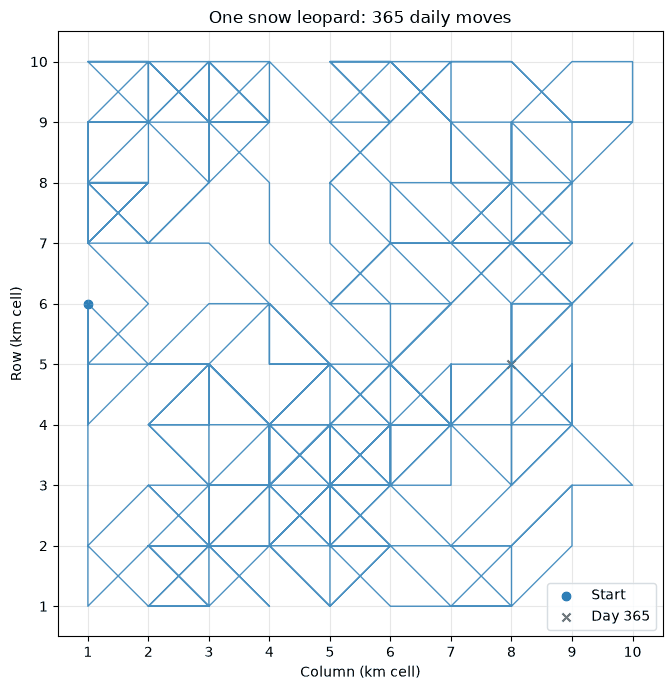

In [25]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(single_year_path % GRID_SIZE + 1,
        single_year_path // GRID_SIZE + 1, linewidth=1, alpha=0.8)
ax.scatter(single_year_path[0] % GRID_SIZE + 1,
           single_year_path[0] // GRID_SIZE + 1, marker="o", label="Start")
ax.scatter(single_year_path[-1] % GRID_SIZE + 1,
           single_year_path[-1] // GRID_SIZE + 1, marker="x", label="Day 365")
ax.set(xlabel="Column (km cell)", ylabel="Row (km cell)",
       xlim=(0.5, 10.5), ylim=(0.5, 10.5),
       title="One snow leopard: 365 daily moves")
ax.set_aspect("equal")
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Response (3.2):** The year-long path is a connected squiggle made of one-cell steps, including diagonals. The checks confirm that it never stays in the same cell and never leaves the 10 × 10 region, and the plot shows it wandering over much of the habitat, as expected for a random walk on a bounded grid.


## 3.3 Multiple leopards
Generalize to a parameterized population N; multiple animals may occupy one cell. Check N = 2 before larger populations. Plot the 365-day paths for N > 2 with a different color for each animal.

**Method:** multiple-leopard movement and paths.

**Heuristic plan for 3.3-3.6 (N leopards, camera, Monte Carlo):**

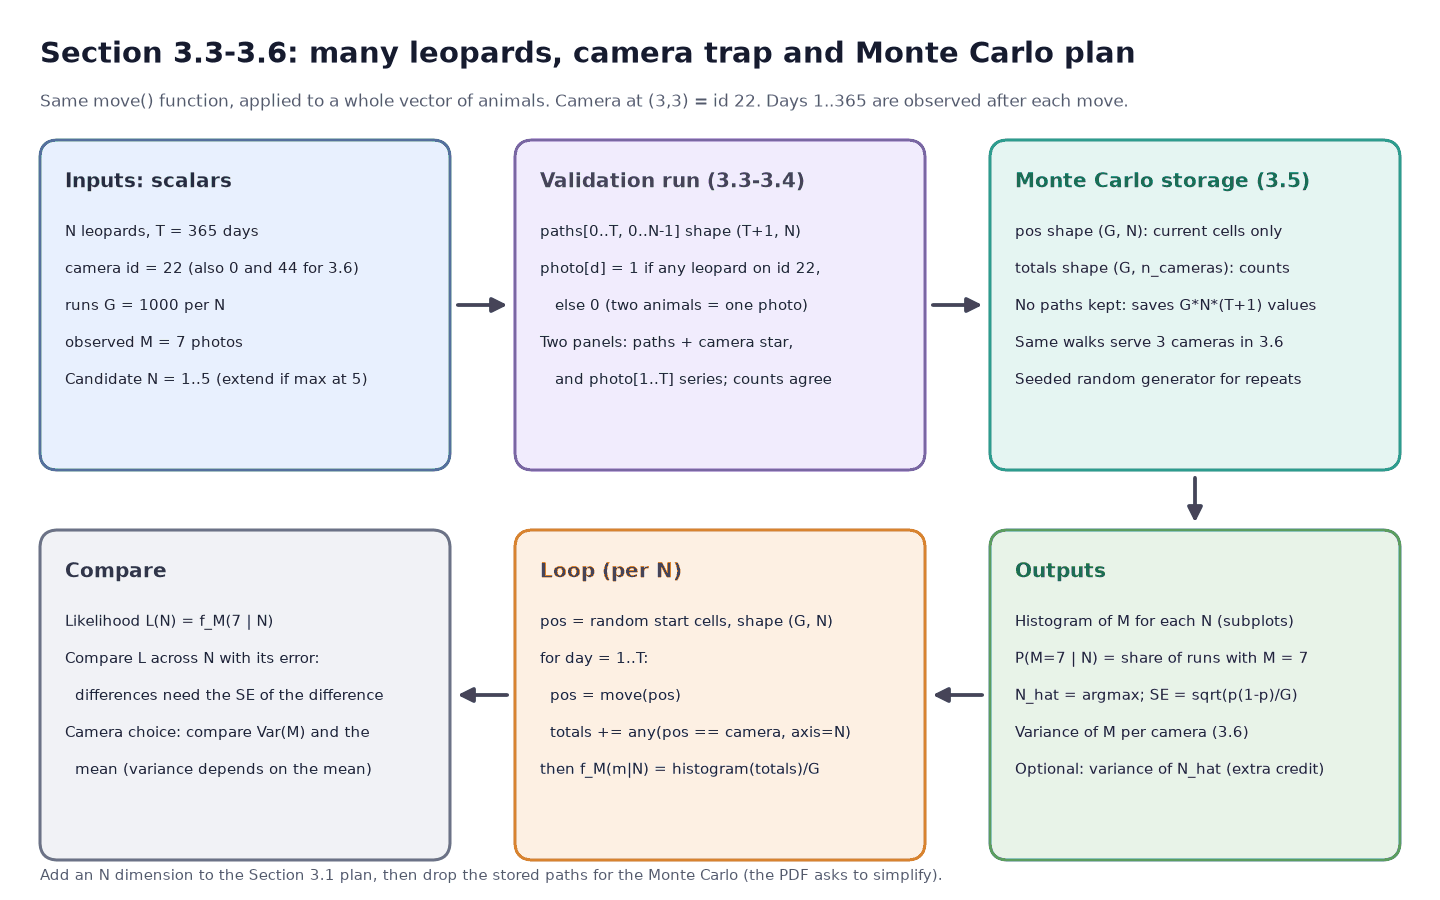


In [26]:
def simulate_paths(n_leopards, days, rng):
    paths = np.empty((days + 1, n_leopards), dtype=np.int16)
    paths[0] = rng.integers(GRID_SIZE**2, size=n_leopards)
    for day in range(days):
        paths[day + 1] = move_positions(paths[day], rng)
    return paths

paths_two = simulate_paths(2, study_days, np.random.default_rng(44))
assert paths_two.shape == (study_days + 1, 2)
assert np.all(paths_two[1:] != paths_two[:-1])
paths_multi = simulate_paths(4, study_days, np.random.default_rng(45))
assert np.all((paths_multi >= 0) & (paths_multi < GRID_SIZE**2))

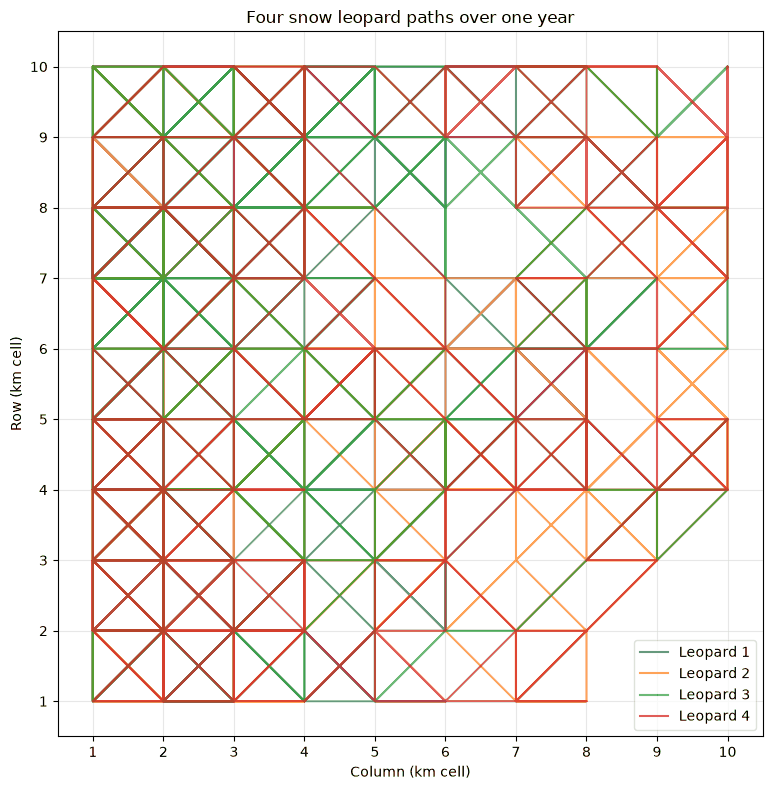

In [27]:
fig, ax = plt.subplots(figsize=(8, 8))
for animal in range(paths_multi.shape[1]):
    ax.plot(paths_multi[:, animal] % GRID_SIZE + 1,
            paths_multi[:, animal] // GRID_SIZE + 1,
            alpha=0.75, label=f"Leopard {animal + 1}")
ax.set(xlabel="Column (km cell)", ylabel="Row (km cell)",
       xlim=(0.5, 10.5), ylim=(0.5, 10.5),
       title="Four snow leopard paths over one year")
ax.set_aspect("equal")
ax.set_xticks(range(1, 11))
ax.set_yticks(range(1, 11))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 3.4 Camera-trap verification
Place one camera at cell (3,3). Record one if at least one leopard occupies that cell on a day, otherwise zero; multiple leopards on one day still count as one photo. Show two subplots: animal paths with the camera marked by a star, and the daily zero-or-one observation series. Confirm the number of recorded observations agrees with the plotted paths. State clearly how the assignment's cell labels map to Python array indices.

**Method:** camera observations, comparison, and two-panel plot.

In [28]:
def cell_id(row, col):
    # PDF/MATLAB labels start at 1; NumPy indexes start at 0.
    if not (1 <= row <= GRID_SIZE and 1 <= col <= GRID_SIZE):
        raise ValueError("Camera row and column must be between 1 and 10")
    return (row - 1) * GRID_SIZE + (col - 1)

camera_label = (3, 3)
camera_id = cell_id(*camera_label)  # Python array location (2, 2).
# Days 1..365 are observed after each daily movement; day 0 is the start.
daily_camera = np.any(paths_multi[1:] == camera_id, axis=1).astype(np.uint8)
assert daily_camera.shape == (study_days,)
assert set(np.unique(daily_camera)).issubset({0, 1})
# Count days with a leopard at (3,3) from the plotted row and column coordinates,
# independently of cell_id() and of daily_camera.
path_rows = paths_multi // GRID_SIZE + 1
path_cols = paths_multi % GRID_SIZE + 1
on_camera_cell = (path_rows == camera_label[0]) & (path_cols == camera_label[1])
map_sightings = int(on_camera_cell[1:].any(axis=1).sum())
assert daily_camera.sum() == map_sightings

print(f"Camera count = {daily_camera.sum()}; map-derived count = {map_sightings}")

Camera count = 19; map-derived count = 19


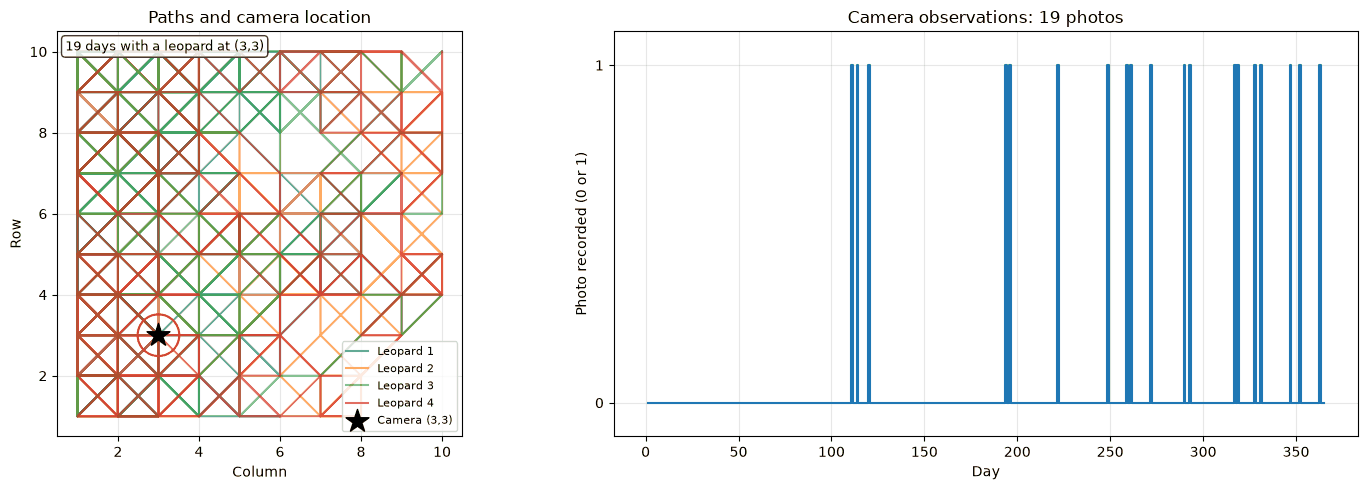

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for animal in range(paths_multi.shape[1]):
    axes[0].plot(paths_multi[:, animal] % GRID_SIZE + 1,
                 paths_multi[:, animal] // GRID_SIZE + 1,
                 alpha=0.65, label=f"Leopard {animal + 1}")
axes[0].scatter(*camera_label[::-1], marker="*", s=300,
                color="black", label="Camera (3,3)", zorder=5)
axes[0].scatter(*camera_label[::-1], marker="o", s=900, facecolors="none",
                edgecolors="tab:red", linewidths=1.5, zorder=4)
axes[0].text(0.02, 0.98, f"{map_sightings} days with a leopard at (3,3)",
             transform=axes[0].transAxes, va="top", fontsize=9,
             bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
axes[0].set(xlabel="Column", ylabel="Row", xlim=(0.5, 10.5),
            ylim=(0.5, 10.5), title="Paths and camera location")
axes[0].set_aspect("equal")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)
axes[1].step(np.arange(1, study_days + 1), daily_camera, where="mid")
axes[1].set(xlabel="Day", ylabel="Photo recorded (0 or 1)",
            ylim=(-0.1, 1.1), yticks=[0, 1],
            title=f"Camera observations: {daily_camera.sum()} photos")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Response (3.4):** The assignment labels a cell as (row, column) with both numbers running from 1 to 10 (MATLAB-style numbering). In the simulation each cell is stored as a single index, (row − 1) × 10 + (column − 1), from 0 to 99, which corresponds to the zero-based array position (row − 1, column − 1). So the camera at (3,3) is id 22, array position (2, 2); (1,1) is id 0 and (5,5) is id 44. To plot, row = id // 10 + 1 and column = id % 10 + 1. In the four-leopard run, the camera recorded 19 photos. A day counts once however many leopards are in the cell. A separate count made from the plotted row and column coordinates also gives 19 days with a leopard at (3,3), so the record matches the paths.


## 3.5 Monte Carlo estimate of population
For a 365-day camera study at (3,3) with seven observed photos, estimate the most likely population N. For each fixed N, repeat the simulation 1,000 times and record the total sightings M per run. During repeated runs, store only what is needed to count sightings; keep full paths for the earlier validation plots.

Start at N = 1 and continue through N = 5; extend to larger N if the greatest estimated probability of M = 7 occurs at the boundary. Plot the sighting distributions as subplots. What is the estimated probability of exactly seven sightings for each N, and which N maximizes it? State simulation uncertainty and the final estimate.

**Method:** repeated simulations, distributions, likelihood comparison, and plots.

In [30]:
camera_labels = [(3, 3), (1, 1), (5, 5)]
camera_ids = np.array([cell_id(*location) for location in camera_labels])
observed_photos = 7
monte_carlo_runs = 1000
monte_carlo_rng = np.random.default_rng(46)

def simulate_camera_counts(n_leopards, runs, days, cameras, rng):
    # Only current positions and total sightings are kept, not full paths.
    # Initial cells are uniform and independent; each subsequent move is local.
    positions = rng.integers(GRID_SIZE**2, size=(runs, n_leopards))
    totals = np.zeros((runs, len(cameras)), dtype=np.int16)
    for day in range(days):
        positions = move_positions(positions, rng)
        totals += np.any(positions[:, :, None] == cameras[None, None, :],
                         axis=1)
    return totals

counts_by_n = {}
likelihood_at_seven = {}
for n_leopards in range(1, 6):
    counts_by_n[n_leopards] = simulate_camera_counts(
        n_leopards, monte_carlo_runs, study_days, camera_ids, monte_carlo_rng)
    likelihood_at_seven[n_leopards] = np.mean(
        counts_by_n[n_leopards][:, 0] == observed_photos)

# Extend beyond five only if the largest tested N remains a likelihood maximum.
while (max(counts_by_n) < 50 and
       likelihood_at_seven[max(counts_by_n)] >= max(likelihood_at_seven.values())):
    n_leopards = max(counts_by_n) + 1
    counts_by_n[n_leopards] = simulate_camera_counts(
        n_leopards, monte_carlo_runs, study_days, camera_ids, monte_carlo_rng)
    likelihood_at_seven[n_leopards] = np.mean(
        counts_by_n[n_leopards][:, 0] == observed_photos)

n_mle = max(likelihood_at_seven, key=likelihood_at_seven.get)
print("N, estimated P(M=7 | N), Monte Carlo standard error")
for n_leopards, probability in likelihood_at_seven.items():
    standard_error = np.sqrt(probability * (1 - probability) / monte_carlo_runs)
    print(f"{n_leopards:2d}, {probability:.4f}, {standard_error:.4f}")
print(f"Highest-likelihood candidate: N = {n_mle}")
if n_mle == max(counts_by_n):
    print("Maximum remains at the tested upper boundary (N=50).")

# Is the best N distinguishable from the others? Compare each candidate with the
# best using the standard error of the difference (independent runs per N).
best_p = likelihood_at_seven[n_mle]
best_se = np.sqrt(best_p * (1 - best_p) / monte_carlo_runs)
print(f"\nComparison with N = {n_mle} (same {monte_carlo_runs} runs per N):")
print("N, P ratio to best, difference, SE of difference, difference / SE")
within_two_se = []
for n_leopards, probability in likelihood_at_seven.items():
    if n_leopards == n_mle:
        continue
    se = np.sqrt(probability * (1 - probability) / monte_carlo_runs)
    se_diff = np.sqrt(best_se**2 + se**2)
    difference = best_p - probability
    z_score = difference / se_diff if se_diff > 0 else np.inf
    if z_score < 2:
        within_two_se.append(n_leopards)
    print(f"{n_leopards:2d}, {probability / best_p:.2f}, {difference:.4f}, {se_diff:.4f}, {z_score:.1f}")
print(f"Candidates not separated from N = {n_mle} by 2 standard errors: {within_two_se}")

N, estimated P(M=7 | N), Monte Carlo standard error
 1, 0.0600, 0.0075
 2, 0.0750, 0.0083
 3, 0.0570, 0.0073
 4, 0.0210, 0.0045
 5, 0.0040, 0.0020
Highest-likelihood candidate: N = 2

Comparison with N = 2 (same 1000 runs per N):
N, P ratio to best, difference, SE of difference, difference / SE
 1, 0.80, 0.0150, 0.0112, 1.3
 3, 0.76, 0.0180, 0.0111, 1.6
 4, 0.28, 0.0540, 0.0095, 5.7
 5, 0.05, 0.0710, 0.0086, 8.3
Candidates not separated from N = 2 by 2 standard errors: [1, 3]


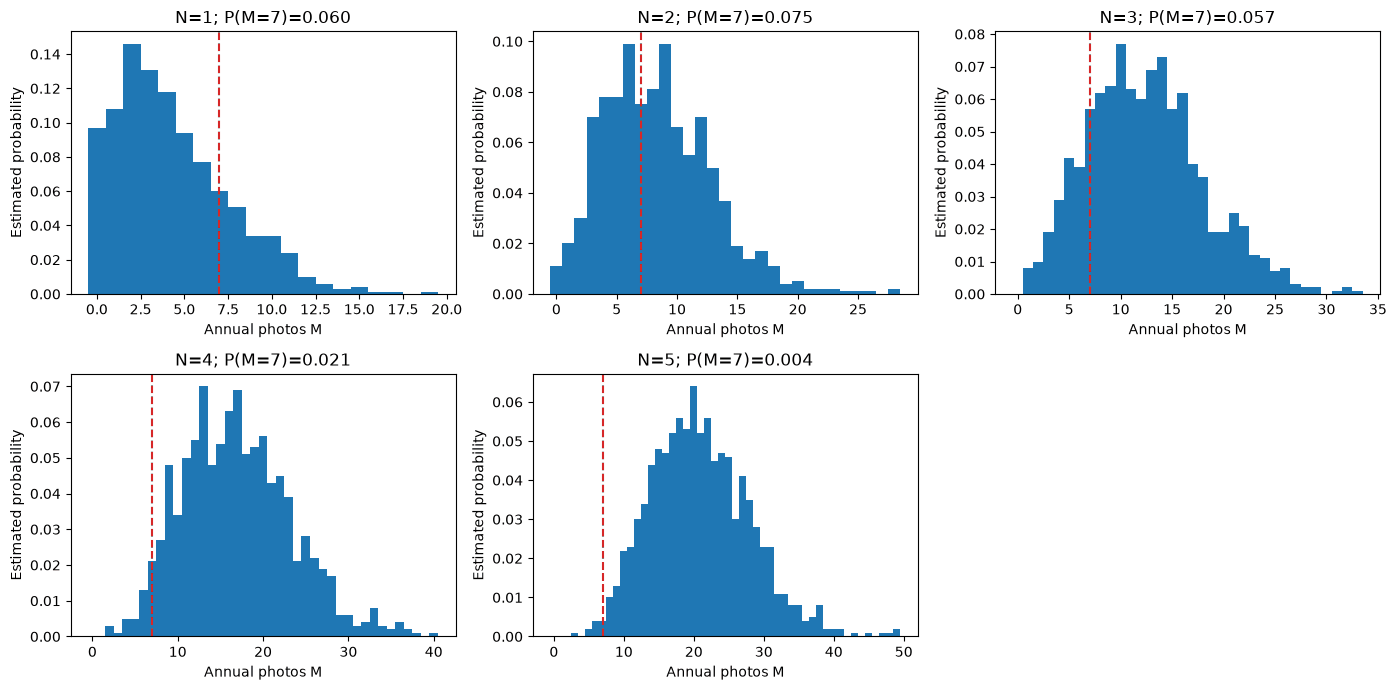

In [31]:
n_plots = len(counts_by_n)
fig, axes = plt.subplots(int(np.ceil(n_plots / 3)), 3,
                         figsize=(14, 3.5 * int(np.ceil(n_plots / 3))),
                         squeeze=False)
for ax, (n_leopards, totals) in zip(axes.flat, counts_by_n.items()):
    observations = totals[:, 0]
    bins = np.arange(observations.max() + 2) - 0.5
    ax.hist(observations, bins=bins, density=True, color="tab:blue")
    ax.axvline(observed_photos, color="tab:red", linestyle="--")
    ax.set(title=f"N={n_leopards}; P(M=7)={likelihood_at_seven[n_leopards]:.3f}",
           xlabel="Annual photos M", ylabel="Estimated probability")
for ax in list(axes.flat)[n_plots:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

In [32]:
# Supplementary check (not requested by the PDF): the same estimate with 20,000 runs
# per N, so the likelihood differences can be compared with much smaller simulation error.
precision_runs = 20_000
precision_rng = np.random.default_rng(48)
precise = {}
print("N, P(M=7 | N) with 20,000 runs, standard error")
for n_leopards in range(1, 6):
    totals = simulate_camera_counts(n_leopards, precision_runs, study_days,
                                    camera_ids[:1], precision_rng)[:, 0]
    precise[n_leopards] = np.mean(totals == observed_photos)
    se = np.sqrt(precise[n_leopards] * (1 - precise[n_leopards]) / precision_runs)
    print(f"{n_leopards:2d}, {precise[n_leopards]:.4f}, {se:.4f}")
precise_best = max(precise, key=precise.get)
print(f"Highest-likelihood N with 20,000 runs: {precise_best}")
print("Likelihood relative to the best:",
      {n: round(p / precise[precise_best], 2) for n, p in precise.items()})


N, P(M=7 | N) with 20,000 runs, standard error
 1, 0.0624, 0.0017


 2, 0.0902, 0.0020


 3, 0.0551, 0.0016


 4, 0.0220, 0.0010


 5, 0.0067, 0.0006
Highest-likelihood N with 20,000 runs: 2
Likelihood relative to the best: {1: np.float64(0.69), 2: np.float64(1.0), 3: np.float64(0.61), 4: np.float64(0.24), 5: np.float64(0.07)}


In [33]:
# Supplementary sensitivity check (not requested by the PDF): does the assumed starting
# position change the population estimate? Camera at (3,3), 10,000 runs per N and start rule.
def simulate_counts_from_start(n_leopards, runs, days, camera, rng, start_rule):
    positions = start_rule(n_leopards, runs, rng)
    totals = np.zeros(runs, dtype=np.int16)
    for _ in range(days):
        positions = move_positions(positions, rng)
        totals += np.any(positions == camera, axis=1)
    return totals

start_rules = {
    "uniform over 100 cells (used above)":
        lambda n, runs, rng: rng.integers(GRID_SIZE**2, size=(runs, n)),
    "stationary (probability proportional to neighbours)":
        lambda n, runs, rng: rng.choice(GRID_SIZE**2, size=(runs, n),
                                        p=neighbor_count / neighbor_count.sum()),
    "all leopards start at the centre cell (5,5)":
        lambda n, runs, rng: np.full((runs, n), cell_id(5, 5)),
}
start_runs = 10_000
for name, rule in start_rules.items():
    start_rng = np.random.default_rng(50)
    probabilities = {}
    for n_leopards in range(1, 6):
        totals = simulate_counts_from_start(n_leopards, start_runs, study_days,
                                            cell_id(*camera_label), start_rng, rule)
        probabilities[n_leopards] = np.mean(totals == observed_photos)
    best = max(probabilities, key=probabilities.get)
    table = {n: round(float(p), 4) for n, p in probabilities.items()}
    print(f"{name}: P(M=7|N) = {table}; highest N = {best}")


uniform over 100 cells (used above): P(M=7|N) = {1: 0.0605, 2: 0.0938, 3: 0.0531, 4: 0.02, 5: 0.0061}; highest N = 2


stationary (probability proportional to neighbours): P(M=7|N) = {1: 0.0587, 2: 0.0938, 3: 0.0546, 4: 0.0202, 5: 0.0059}; highest N = 2


all leopards start at the centre cell (5,5): P(M=7|N) = {1: 0.0627, 2: 0.0911, 3: 0.0519, 4: 0.0173, 5: 0.0055}; highest N = 2


**Response (3.5):** *Estimated probability of exactly seven sightings* (1,000 runs per N): 0.060 for N = 1, **0.075 for N = 2**, 0.057 for N = 3, 0.021 for N = 4 and 0.004 for N = 5, with simulation standard errors of about 0.0075, 0.0083, 0.0073, 0.0045 and 0.0020. The maximum is at N = 2, inside the tested range, so no larger N was needed. *Uncertainty:* the standard error of the difference is about 0.011, so N = 2 is only 1.3 and 1.6 standard errors above N = 1 and N = 3, which this run alone does not separate; N = 4 and N = 5 are clearly lower (5.7 and 8.3 standard errors). A larger simulation with 20,000 runs per N (standard errors about 0.002) gives 0.062, 0.090, 0.055, 0.022 and 0.007: N = 2 is still the maximum, with N = 1 at 69% and N = 3 at 61% of its likelihood. The result does not depend on the assumed starting position: starting uniformly, from the stationary distribution, or all at the center, N = 2 is the maximum in each case. *Best guess:* **N̂ = 2 snow leopards**, with 1 to 3 remaining plausible given one camera and one year of data. Even at N = 2 the chance of seeing exactly seven photos is under 10%, so a single study carries a lot of noise.


## 3.6 Choose a camera location
With N = 3 and 1,000 year-long runs per location, compare cameras at (3,3), (1,1), and (5,5). Reuse the (3,3) results if applicable. Compare the variance of each location's sighting-count distribution. Which has the smallest and largest variance? What does this mean, and where would you recommend placing the camera before the field experiment?

**Method:** location comparison, distributions, variances, and plot.

In [34]:
# The N=3 simulations above recorded all three camera cells on the same paths.
counts_n3 = counts_by_n[3]
camera_variances = np.var(counts_n3, axis=0, ddof=1)
# Bootstrap the 1,000 runs to see how much each sample variance could move.
bootstrap_rng = np.random.default_rng(49)
bootstrap_variances = np.array([
    np.var(counts_n3[bootstrap_rng.integers(0, len(counts_n3), len(counts_n3))],
           axis=0, ddof=1)
    for _ in range(2000)
])
variance_low, variance_high = np.percentile(bootstrap_variances, [2.5, 97.5], axis=0)
print("Camera location, mean photos, sample variance, 95% bootstrap interval, variance / mean")
for j, (location, totals, variance) in enumerate(
        zip(camera_labels, counts_n3.T, camera_variances)):
    print(f"{location}, {totals.mean():.3f}, {variance:.3f}, "
          f"[{variance_low[j]:.1f}, {variance_high[j]:.1f}], {variance / totals.mean():.2f}")

Camera location, mean photos, sample variance, 95% bootstrap interval, variance / mean
(3, 3), 12.367, 31.674, [28.8, 34.4], 2.56
(1, 1), 4.541, 12.531, [11.1, 14.0], 2.76
(5, 5), 12.560, 20.547, [18.5, 22.6], 1.64


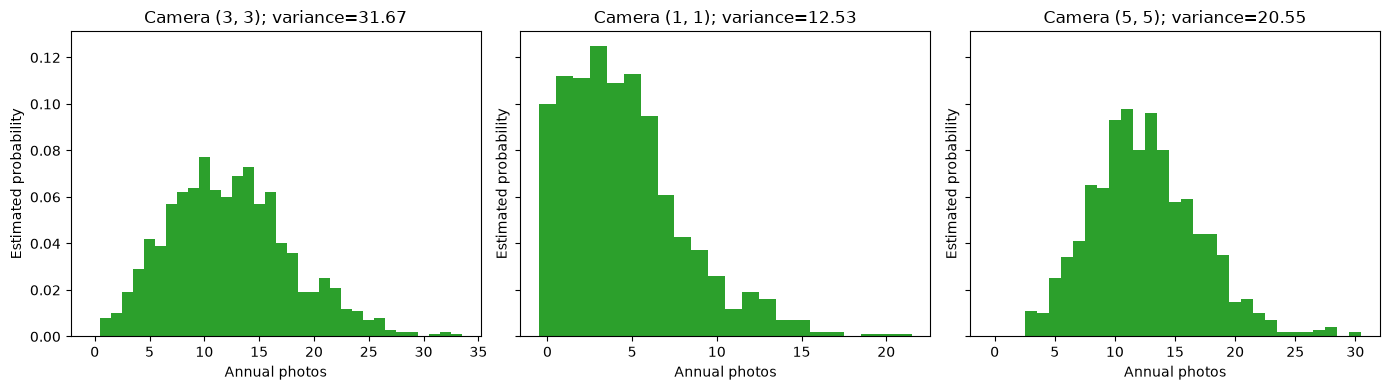

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, location, totals, variance in zip(
        axes, camera_labels, counts_n3.T, camera_variances):
    bins = np.arange(totals.max() + 2) - 0.5
    ax.hist(totals, bins=bins, density=True, color="tab:green")
    ax.set(title=f"Camera {location}; variance={variance:.2f}",
           xlabel="Annual photos", ylabel="Estimated probability")
plt.tight_layout()
plt.show()

In [36]:
# Signal per added leopard relative to noise, from the same 1,000-run simulations.
# A camera separates population sizes well when one more leopard moves the mean count
# by much more than the spread of a single year's count.
mean_by_n = {n: counts_by_n[n].mean(axis=0) for n in (2, 3, 4)}
extra_photos_per_leopard = (mean_by_n[4] - mean_by_n[2]) / 2
spread_at_n3 = counts_by_n[3].std(axis=0, ddof=1)
print("Camera location, extra photos per added leopard, SD of M at N=3, ratio")
for j, location in enumerate(camera_labels):
    print(f"{location}, {extra_photos_per_leopard[j]:.2f}, {spread_at_n3[j]:.2f}, "
          f"{extra_photos_per_leopard[j] / spread_at_n3[j]:.2f}")


Camera location, extra photos per added leopard, SD of M at N=3, ratio
(3, 3), 4.30, 5.63, 0.76
(1, 1), 1.59, 3.54, 0.45
(5, 5), 4.04, 4.53, 0.89


**Response (3.6):** *Variances* (N = 3, 1,000 runs): (3,3) has a mean of 12.4 photos and variance 31.7; (1,1) has mean 4.5 and variance 12.5; (5,5) has mean 12.6 and variance 20.5. The camera at **(1,1) has the smallest variance and the camera at (3,3) has the largest**. The 95% bootstrap intervals for the variance, (1,1): 11.1–14.0, (3,3): 28.8–34.4 and (5,5): 18.5–22.6, do not overlap, so the ordering is not simulation noise.

*What this means:* the variance describes how much a single year's count at that camera varies between otherwise identical years, so with a large variance one year's count is a less reliable guide to the expected count. The variance alone mixes two things: how many animals the camera sees (its mean) and how irregular those sightings are. The corner camera has the smallest variance mainly because it sees few animals (variance per average photo is 2.76, the highest of the three), while (5,5) and (3,3) record the same number of photos on average but (5,5) has about a third less variance (1.64 per average photo versus 2.56).

*Recommendation:* **place the camera at (5,5).** To estimate N, the count has to change clearly when N changes, compared with how much it varies from year to year. One more leopard adds about 4.0 photos at (5,5), 4.3 at (3,3) and only 1.6 at (1,1). Dividing by the spread of a year's count at N = 3 (4.5, 5.6 and 3.5) gives 0.89, 0.76 and 0.45. So (5,5) separates different population sizes best, (3,3) is next, and (1,1) is worst even though its raw variance is the smallest. Section 3.7 confirms this with the variance of the population estimate itself, which is lowest at (5,5) (1.07), then (3,3) (1.45), then (1,1) (1.90).


## 3.7 Extra credit: precision of the population estimate
Explain why the variance of sightings M at a location differs from the variance of the population estimator N̂ based on maximum likelihood. Which criterion better measures precision of the population estimate? Describe how to estimate the variance of N̂ across camera locations.

**Response:** The variance of M describes the spread of the data at a known N. The variance of the estimator N̂ describes the spread of our answer, and it depends on how the distribution of M shifts as N changes: N̂ is the N whose distribution makes the observed count most likely, so a camera whose counts barely change with N, or whose distributions for neighboring N overlap heavily, gives an imprecise N̂ even if Var(M) is small. The variance of N̂ is the better measure of how precisely we know the number of snow leopards, since it is the quantity we report. To estimate it for each camera: fix a true N (here 3), simulate many independent year-long studies, convert each study's count to an N̂ by the maximum-likelihood rule using the Monte Carlo probability tables, and take the variance of those estimates across studies. The calculation below does this and gives Var(N̂) = 1.45 for (3,3), 1.90 for (1,1) and 1.07 for (5,5). The ranking differs from the ranking of Var(M): (1,1) has the smallest Var(M) but the largest Var(N̂), and (5,5) has the smallest Var(N̂). Caveats: the estimates are limited to N = 1 to 5 (12 to 19% fall at 5, which understates the spread), the probability tables come from only 1,000 runs per N, and only one true N was tested.

**Optional extension (extra extra credit):** estimate and compare those estimator variances.

In [37]:
# Extra extra credit: independently repeat N=3 studies, then estimate N
# from the Monte Carlo likelihood table at each camera location.
evaluation_rng = np.random.default_rng(47)
evaluation_counts = simulate_camera_counts(
    3, monte_carlo_runs, study_days, camera_ids, evaluation_rng)
# Estimates are conditional on the candidate N values simulated above; a limited
# candidate range truncates the estimates and understates their spread.
candidate_n = np.array(sorted(counts_by_n))
estimated_n_by_camera = {}
for camera_index, location in enumerate(camera_labels):
    # The same small pseudocount handles unseen sighting totals; all
    # candidate populations have the same 1,000 training runs.
    likelihood_table = np.stack([
        (np.bincount(counts_by_n[n][:, camera_index],
                     minlength=study_days + 1) + 0.5)
        / (monte_carlo_runs + 0.5 * (study_days + 1))
        for n in candidate_n
    ])
    estimates = candidate_n[
        np.argmax(likelihood_table[:, evaluation_counts[:, camera_index]], axis=0)
    ]
    estimated_n_by_camera[location] = estimates
    variance = np.var(estimates, ddof=1)
    print(f"Camera {location}: Var(N_MLE) = {variance:.3f}; candidates "
          f"{candidate_n.min()}-{candidate_n.max()}; share of estimates at the largest "
          f"candidate = {np.mean(estimates == candidate_n.max()):.3f}")

Camera (3, 3): Var(N_MLE) = 1.452; candidates 1-5; share of estimates at the largest candidate = 0.150
Camera (1, 1): Var(N_MLE) = 1.899; candidates 1-5; share of estimates at the largest candidate = 0.188
Camera (5, 5): Var(N_MLE) = 1.072; candidates 1-5; share of estimates at the largest candidate = 0.120


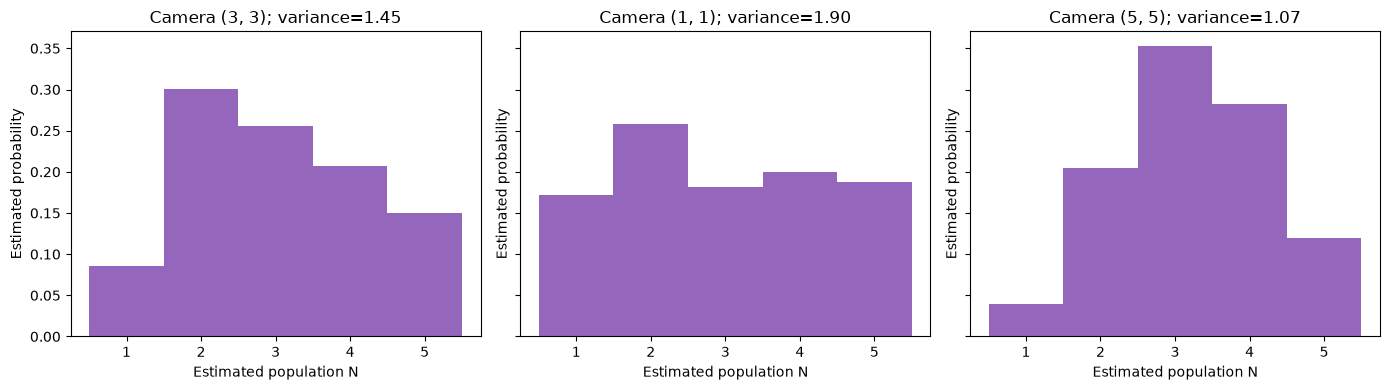

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, location in zip(axes, camera_labels):
    estimates = estimated_n_by_camera[location]
    ax.hist(estimates, bins=np.arange(0.5, candidate_n.max() + 1.5),
            density=True, color="tab:purple")
    ax.set(title=f"Camera {location}; variance={np.var(estimates, ddof=1):.2f}",
           xlabel="Estimated population N", ylabel="Estimated probability")
plt.tight_layout()
plt.show()

# Summary of results
When the analysis is complete, summarize the surface intersection, population-model behaviors, snow-leopard population estimate, and camera-location recommendation. Separate computed findings from modeling assumptions and simulation uncertainty.

**Summary:**

*Computed findings.* The surfaces z = x² + sin y + xy and z = x + y intersect where (x − 1)(x + y) + sin y = 0; at x = 1 there are three solutions, y = −π, 0 and π, with z = −2.14, 1 and 4.14. The koala growth rate is r = 1/6; unrestricted growth is exponential, and with carrying capacity K = 1000 the koalas settle smoothly on K. The same logistic update gives damped oscillations, cycles and chaos for larger r, and negative populations above r = 3. Beetles (r = 4, K = 1,000,000) overshoot and the update becomes negative for every start except exactly K. In competition the two species' balance conditions coincide, so the long-run state is a line of equilibria (koalas + 0.001 × beetles = 1000) at a point set by the initial populations. In predator-prey with the capacity N/12, any introduction of at least one snake eventually collapses the koalas (after 70 years for 1 snake, fewer for more), so there is no threshold; with a smaller snake capacity (a fraction f ≤ 0.09 of that) there is one, for example 16 safe snakes versus 17 collapsing at f = 0.05. For the snow leopards the most likely population is N̂ = 2 (1 to 3 plausible), and the best camera location among the three is (5,5): it separates population sizes best (one more leopard adds 4.0 photos against a year-to-year spread of 4.5) and gives the lowest variance of the estimate, even though (1,1) has the smallest raw variance.

*Modeling assumptions.* The specified equations are used exactly, and a simulation ends at its first negative or undefined value. The beetle growth rate is r = 4 (parents die), the conversion constants are β_koala = 0.001 and β_beetle = 1000, and the snake carrying capacity is K_snakes = N/12 (varied in 2.9c, where the threshold results appear). Leopards start in uniformly random cells (checked against stationary and center starts). The zero-floor and limited-kills comparisons are optional modified rules, not part of the specified model.

*Simulation uncertainty.* Probabilities of seven sightings have standard errors of about 0.004 to 0.008 with 1,000 runs per N, so N = 1 and N = 3 are not separated from N = 2 by that run alone; a 20,000-run check keeps N = 2 as the maximum. Camera variances have bootstrap intervals that do not overlap, but the variance of N̂ is limited to the candidate range N = 1 to 5 and one true N.